In [1]:
import random

import numpy as np
import json
import seaborn as sns
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.tree import DecisionTreeClassifier
from sklearn import svm
from sklearn.linear_model import SGDClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_val_score
import os
import time
from sklearn.metrics import confusion_matrix, cohen_kappa_score
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, cohen_kappa_score
from sklearn.metrics import ConfusionMatrixDisplay

class Results:
    accuracy = pd.DataFrame()
    precision = pd.DataFrame()
    recall = pd.DataFrame()
    f1 = pd.DataFrame()
    kappa = pd.DataFrame()
    train_accuracy = pd.DataFrame()
    train_precision = pd.DataFrame()
    train_recall = pd.DataFrame()
    train_f1 = pd.DataFrame()
    train_kappa = pd.DataFrame()
    cv_mean = pd.DataFrame()
    cv_stddev = pd.DataFrame()
    train_error_rate = pd.DataFrame()
    gap = pd.DataFrame()
    error_rate = pd.DataFrame()
    train_time = pd.DataFrame()
    infer_time = pd.DataFrame()

    accuracy["Setup"] = ""
    precision["Setup"] = ""
    recall["Setup"] = ""
    f1["Setup"] = ""
    cv_mean["Setup"] = ""
    cv_stddev["Setup"] = ""
    kappa["Setup"] = ""
    error_rate["Setup"] = ""
    train_time["Setup"] = ""
    infer_time["Setup"] = ""
    train_accuracy["Setup"] = ""
    train_precision["Setup"] = ""
    train_recall["Setup"] = ""
    train_f1["Setup"] = ""
    train_kappa["Setup"] = ""
    train_error_rate["Setup"] = ""
    gap["Setup"] = ""

    accuracy.set_index('Setup')
    precision.set_index('Setup')
    recall.set_index('Setup')
    f1.set_index('Setup')
    cv_mean.set_index('Setup')
    cv_stddev.set_index('Setup')
    kappa.set_index('Setup')
    error_rate.set_index('Setup')
    train_time.set_index('Setup')
    infer_time.set_index('Setup')
    train_accuracy.set_index('Setup')
    train_precision.set_index('Setup')
    train_recall.set_index('Setup')
    train_f1.set_index('Setup')
    train_kappa.set_index('Setup')
    train_error_rate.set_index('Setup')
    gap.set_index('Setup')

    def addModel(self, name):
        self.accuracy[name] = ""
        self.precision[name] = ""
        self.recall[name] = ""
        self.f1[name] = ""
        self.cv_mean[name] = ""
        self.cv_stddev[name] = ""
        self.kappa[name] = ""
        self.error_rate[name] = ""
        self.train_time[name] = ""
        self.infer_time[name] = ""
        self.train_accuracy[name] = ""
        self.train_precision[name] = ""
        self.train_recall[name] = ""
        self.train_f1[name] = ""
        self.train_kappa[name] = ""
        self.train_error_rate[name] = ""
        self.gap[name] = ""

    def addResults(self, _acc, _precision, _recall, _f1, _cv_mean, _cv_stddev, _kappa, _error_rate, _train_time, _infer_time, _train_acc, _train_precision, _train_recall, _train_f1, _train_kappa, _train_error_rate, _gap):
        self.accuracy.loc[len(self.accuracy)] = _acc
        self.precision.loc[len(self.precision)] = _precision
        self.recall.loc[len(self.recall)] = _recall
        self.f1.loc[len(self.f1)] = _f1
        self.cv_mean.loc[len(self.cv_mean)] = _cv_mean
        self.cv_stddev.loc[len(self.cv_stddev)] = _cv_stddev
        self.kappa.loc[len(self.kappa)] = _kappa
        self.error_rate.loc[len(self.error_rate)] = _error_rate
        self.train_time.loc[len(self.train_time)] = _train_time
        self.infer_time.loc[len(self.infer_time)] = _infer_time
        self.train_accuracy.loc[len(self.accuracy)] = _train_acc
        self.train_precision.loc[len(self.precision)] = _train_precision
        self.train_recall.loc[len(self.recall)] = _train_recall
        self.train_f1.loc[len(self.f1)] = _train_f1
        self.train_kappa.loc[len(self.kappa)] = _train_kappa
        self.train_error_rate.loc[len(self.error_rate)] = _train_error_rate
        self.gap.loc[len(self.gap)] = _gap

    def printCSV(self, output_folder="Classification"):
      # Cria a pasta com o subdiretório
        full_path = os.path.join("Classification", output_folder)
        os.makedirs(full_path, exist_ok=True)
        self.accuracy.to_csv(f'{full_path}/classification_all_accuracy.csv', index=False, float_format='%.3f')
        self.precision.to_csv(f'{full_path}/classification_all_precision.csv', index=False, float_format='%.3f')
        self.recall.to_csv(f'{full_path}/classification_all_recall.csv', index=False, float_format='%.3f')
        self.f1.to_csv(f'{full_path}/classification_all_f1.csv', index=False, float_format='%.3f')
        self.cv_mean.to_csv(f'{full_path}/classification_all_cv_mean.csv', index=False, float_format='%.3f')
        self.cv_stddev.to_csv(f'{full_path}/classification_all_cv_stddev.csv', index=False, float_format='%.3f')
        self.kappa.to_csv(f'{full_path}/classification_all_kappa.csv', index=False, float_format='%.3f')
        self.error_rate.to_csv(f'{full_path}/classification_all_error_rate.csv', index=False, float_format='%.3f')
        self.train_time.to_csv(f'{full_path}/classification_all_train_time.csv', index=False, float_format='%.3f')
        self.infer_time.to_csv(f'{full_path}/classification_all_infer_time.csv', index=False, float_format='%.3f')

def initialize_data_frame():
    pd.set_option('display.max_columns', None)
    pd.set_option('display.width', 2000)
    sns.set(rc={'figure.figsize':(19.20, 10.80)})


def get_dungeon_data_frame():
    with open('backup.json') as data_file:
        json_data = json.load(data_file)
    return pd.DataFrame(json_data['__collections__']['dungeons']).T


def get_user_data_frame():
    with open('backup.json') as data_file:
        json_data = json.load(data_file)
    return pd.DataFrame(json_data['__collections__']['users']).T


def drop_invalid_rows(_data_frame):
    _data_frame.drop(_data_frame[_data_frame['UniqueRoomsEntered'] == 0].index, inplace=True)
    return _data_frame


def drop_unused_columns(_data_frame):
    _data_frame.drop('__collections__', inplace=True, axis=1)
    _data_frame = _data_frame.drop(list(_data_frame.filter(regex='^Total.*Quests')), axis=1)
    _data_frame.drop('CompletedQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedKillQuests', inplace=True, axis=1)
    _data_frame.rename(columns={'CompletedDamageQuests': 'CompletedKillQuests'}, inplace=True)
    _data_frame.drop('TreasuresCollected', inplace=True, axis=1)
    _data_frame.drop('TotalNpcs', inplace=True, axis=1)
    _data_frame.drop('WeaponName', inplace=True, axis=1)
    _data_frame.drop('HeatMap', inplace=True, axis=1)
    return _data_frame


def get_percentages(_data_frame):
    _data_frame['LockUsage'] = _data_frame['LocksOpened'].div(_data_frame['TotalLocks'].values)*100
    _data_frame['KeyCollection'] = _data_frame['KeysCollected'].div(_data_frame['TotalKeys'].values)*100
    _data_frame['MapCompletion'] = _data_frame['UniqueRoomsEntered'].div(_data_frame['TotalRooms'].values)*100
    _data_frame['RoomRevisitRate'] = _data_frame['RoomsEntered'].div(_data_frame['TotalRooms'].values)*100
    _data_frame['EnemyKillRate'] = _data_frame['EnemiesKilled'].div(_data_frame['TotalEnemies'].values)*100
    _data_frame['TotalAttempts'] = _data_frame['TotalWins'] + _data_frame['TotalDeaths'].values
    _data_frame['TotalAttempts'] = _data_frame['TotalAttempts'].astype(float)
    _data_frame['TotalWins'] = _data_frame['TotalWins'].astype(float)
    _data_frame['Success Rate'] = _data_frame['TotalAttempts'].div(_data_frame['TotalWins'].values)*100
    _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
    return _data_frame


def drop_processed_columns(_data_frame):
    _data_frame.drop('LocksOpened', inplace=True, axis=1)
    _data_frame.drop('TotalLocks', inplace=True, axis=1)
    _data_frame.drop('KeysCollected', inplace=True, axis=1)
    _data_frame.drop('TotalKeys', inplace=True, axis=1)
    _data_frame.drop('EnemiesKilled', inplace=True, axis=1)
    _data_frame.drop('TotalEnemies', inplace=True, axis=1)
    _data_frame.drop('TotalAttempts', inplace=True, axis=1)
    _data_frame.drop('TotalWins', inplace=True, axis=1)
    _data_frame.drop('TotalDeaths', inplace=True, axis=1)
    _data_frame.drop('NpcsInteracted', inplace=True, axis=1)
    _data_frame.drop('RoomsEntered', inplace=True, axis=1)
    _data_frame.drop('TotalRooms', inplace=True, axis=1)
    _data_frame.drop('UniqueRoomsEntered', inplace=True, axis=1)
    _data_frame.drop('TotalTreasure', inplace=True, axis=1)
    return _data_frame


def split_preform_answers(_data_frame):
    _data_frame[['A', 'C', 'I', 'M']] = _data_frame['PreFormAnswers'].str.split(',', expand=True)
    _data_frame['A'] = _data_frame['A'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    _data_frame['C'] = _data_frame['C'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    _data_frame['I'] = _data_frame['I'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    _data_frame['M'] = _data_frame['M'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    return _data_frame


def drop_quest_data(_data_frame):
    _data_frame = _data_frame.drop(list(_data_frame.filter(regex='Quest')), axis=1)
    return _data_frame


def drop_player_data(_data_frame):
    _data_frame.drop('A', inplace=True, axis=1)
    _data_frame.drop('C', inplace=True, axis=1)
    _data_frame.drop('I', inplace=True, axis=1)
    _data_frame.drop('M', inplace=True, axis=1)
    _data_frame.drop('PostFormAnswers', inplace=True, axis=1)
    _data_frame.drop('PlayerId', inplace=True, axis=1)
    return _data_frame


def drop_gameplay_data(_data_frame):
    _data_frame.drop('TimeToFinish', inplace=True, axis=1)
    _data_frame.drop('LockUsage', inplace=True, axis=1)
    _data_frame.drop('KeyCollection', inplace=True, axis=1)
    _data_frame.drop('MapCompletion', inplace=True, axis=1)
    _data_frame.drop('EnemyKillRate', inplace=True, axis=1)
    return _data_frame


def drop_terminal_quest_data(_data_frame):
    _data_frame.drop('CompletedReportQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedListenQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedExploreQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedExchangeQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedKillQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedGiveQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedGoToQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedGatherQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedReadQuests', inplace=True, axis=1)
    return _data_frame


def augment_dataframe_with_scaling(df, y, n, scale_factor):
    """
    Augments the DataFrame by adding `n` new rows, scaling numeric columns by a given factor.
    The new rows inherit the same 'y' values as their corresponding sampled rows.

    Parameters:
        df (pd.DataFrame): Original DataFrame with numeric columns and a 'y' column.
        n (int): Number of new rows to generate.
        scale_factor (float): The factor by which numeric columns will be scaled.

    Returns:
        pd.DataFrame: DataFrame with the original and new rows.
    """
    # Identify numeric columns, excluding 'y'
    numeric_columns = df.select_dtypes(include=['number']).columns.difference(y)
    # Randomly sample `n` rows from the original DataFrame
    sampled_rows = df.sample(n=n, replace=True).reset_index(drop=True)

    # Scale numeric columns
    for col in numeric_columns:
        sampled_rows[col] *= scale_factor

    # Append the scaled rows to the original DataFrame
    augmented_df = pd.concat([df, sampled_rows], ignore_index=True)

    return augmented_df


def augment_data_random(_df, y, n):
    """
    Augments the DataFrame by adding `n` new rows.
    - Adds noise to numerical columns using a normal distribution.
    - Retains the same 'y' values for the newly added rows as their corresponding sampled rows.

    Parameters:
        _df (pd.DataFrame): Original DataFrame with numeric columns and a 'y' column.
        y (list): the column(s) that will have their value retained
        n (int): Number of new rows to generate.

    Returns:
        pd.DataFrame: DataFrame with the original and new rows.
    """
    # Identify float and integer columns, excluding 'y'
    float_columns = _df.select_dtypes(include=['float']).columns.difference(y)
    int_columns = _df.select_dtypes(include=['integer']).columns.difference(y)

    # Randomly sample `n` rows from the original DataFrame
    sampled_rows = _df.sample(n=n, replace=True).reset_index(drop=True)

    # Add noise to float columns
    for col in float_columns:
        if random.randint(1, 100) > 50:
            std = _df[col].std()
            noise = np.random.normal(loc=0, scale=std, size=n)
            sampled_rows[col] += noise

    for col in int_columns:
        if random.randint(1, 100) > 50:
            std = _df[col].std()
            noise = np.random.normal(loc=0, scale=std, size=n)
            sampled_rows[col] += noise

    # Ensure integer columns remain integers
    sampled_rows[int_columns] = sampled_rows[int_columns].round().astype(int)

    # Append the sampled (augmented) rows to the original DataFrame
    augmented_df = pd.concat([_df, sampled_rows], ignore_index=True)
    return augmented_df


def classify(_df, models, output_folder):
    _df.drop('PostFormAnswers', axis=1, inplace=True)
    _df.drop('PlayerId', axis=1, inplace=True)
    _df.drop('InputProfile', axis=1, inplace=True)
    _df.drop('LevelName', axis=1, inplace=True)
    _df['PreFormAnswers'] = _df['PreFormAnswers'].apply(lambda x: 'A=' + str(x[0]) + ", C=" + str(x[1]) + ", I=" + str(x[2]) +
                                                                  ", M=" + str(x[3]))
    _df = split_preform_answers(_df)
    n = _df.shape[0]

    _df.describe().to_csv('descriptive_statistics.csv')


    _dfnoise = augment_data_random(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n)
    _dfscale = augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.05)
    _dfnoise2 = augment_data_random(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], 2*n)
    _dfscale2 = augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.05)
    _dfscale2 = augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 0.95)
    _dfmixed = augment_data_random(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n)
    _dfmixed = pd.concat([_dfmixed, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.05)], ignore_index=True)
    _dfmixed10 = augment_data_random(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], 6*n)
    _dfmixed10 = pd.concat([_dfmixed10, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.05)], ignore_index=True)
    _dfmixed10 = pd.concat([_dfmixed10, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 0.95)], ignore_index=True)
    _dfmixed10 = pd.concat([_dfmixed10, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.10)], ignore_index=True)
    _dfmixed10 = pd.concat([_dfmixed10, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 0.9)], ignore_index=True)

    dataframes = [#_df, _dfnoise, _dfscale, _dfnoise2, _dfscale2, _dfmixed,
                  _dfmixed10]
    experiment_names = [#'Baseline', '1xN', '1xS-1_05', '2xN', '2xS-1_05+0_95', '1xS-1_05+1xN',
                        '6xN+4xS-1_05+0_95+1_1+0_9']

    strategies = [#'Original', '1xNoise', '1xScale', '2xN', '2xScale', '1xN+1xS',
                  '6xN+4xS']

    results = Results()
    # LIMPA COMPLETAMENTE TODOS OS RESULTADOS ANTERIORES

    results.accuracy = pd.DataFrame(columns=["Setup"])
    results.precision = pd.DataFrame(columns=["Setup"])
    results.recall = pd.DataFrame(columns=["Setup"])
    results.f1 = pd.DataFrame(columns=["Setup"])
    results.kappa = pd.DataFrame(columns=["Setup"])

    results.train_accuracy = pd.DataFrame(columns=["Setup"])
    results.train_precision = pd.DataFrame(columns=["Setup"])
    results.train_recall = pd.DataFrame(columns=["Setup"])
    results.train_f1 = pd.DataFrame(columns=["Setup"])
    results.train_kappa = pd.DataFrame(columns=["Setup"])

    results.cv_mean = pd.DataFrame(columns=["Setup"])
    results.cv_stddev = pd.DataFrame(columns=["Setup"])

    results.train_error_rate = pd.DataFrame(columns=["Setup"])
    results.error_rate = pd.DataFrame(columns=["Setup"])
    results.gap = pd.DataFrame(columns=["Setup"])

    results.train_time = pd.DataFrame(columns=["Setup"])
    results.infer_time = pd.DataFrame(columns=["Setup"])

    for model in models:
        results.addModel(model)

    for i in range(len(strategies)):
        _experimentdf = dataframes[i]

        profiles = _experimentdf['PreFormAnswers']
        _experimentdf.drop('PreFormAnswers', axis=1, inplace=True)
        _experimentdf.drop('A', axis=1, inplace=True)
        _experimentdf.drop('C', axis=1, inplace=True)
        _experimentdf.drop('I', axis=1, inplace=True)
        _experimentdf.drop('M', axis=1, inplace=True)
        _experimentdf.drop('Success Rate', axis=1, inplace=True)
        X_train, X_test, y_train, y_test = train_test_split(_experimentdf, profiles, test_size=0.3, random_state=42)

        min_max_scaler = MinMaxScaler()
        X_train = min_max_scaler.fit_transform(X_train)

        experiment_name = experiment_names[i]

        train_accuracy = [experiment_name]
        train_precision = [experiment_name]
        train_recall = [experiment_name]
        train_f1score = [experiment_name]
        train_kappa = [experiment_name]
        train_error_rate = [experiment_name]
        accuracy = [experiment_name]
        precision = [experiment_name]
        recall = [experiment_name]
        f1score = [experiment_name]
        cv_mean = [experiment_name]
        cv_stddev = [experiment_name]
        kappa = [experiment_name]
        error_rate = [experiment_name]
        train_time = [experiment_name]
        infer_time = [experiment_name]
        gap = [experiment_name]

        for name, model in models.items():
            start_train = time.perf_counter()
            model.fit(X_train, y_train)
            train_pred = model.predict(X_train)
            end_train = time.perf_counter()
            #train_time = end_train - start_train
            #print(f"Tempo de treino: {train_time:0.4f} segundos")

            start_pred = time.perf_counter()
            pred = model.predict(X_test)
            end_pred = time.perf_counter()
            #infer_time = end_pred - start_pred
            #print(f"Tempo de treino: {infer_time:0.4f} segundos")

            train_accuracy.append(accuracy_score(y_train, train_pred))
            train_precision.append(precision_score(y_train, train_pred, average='weighted'))
            train_recall.append(recall_score(y_train, train_pred, average='weighted'))
            train_f1score.append(f1_score(y_train, train_pred, average='weighted'))
            train_error_rate.append(1 - accuracy_score(y_train, train_pred))
            train_kappa.append(cohen_kappa_score(y_train, train_pred))

            accuracy.append(accuracy_score(y_test, pred))
            precision.append(precision_score(y_test, pred, average='weighted'))
            recall.append(recall_score(y_test, pred, average='weighted'))
            f1score.append(f1_score(y_test, pred, average='weighted'))
            error_rate.append(1 - accuracy_score(y_test, pred))
            kappa.append(cohen_kappa_score(y_test, pred))
            gap.append(accuracy_score(y_train, train_pred) - accuracy_score(y_test, pred))
            train_time.append(end_train - start_train)
            infer_time.append(end_pred - start_pred)

            # ---------- Matriz de confusão ----------
            cm = confusion_matrix(y_test, pred)
            # Cria a pasta com output_folder no caminho
            full_path = os.path.join("Classification/", output_folder)
            os.makedirs(full_path, exist_ok=True)

            with open(f"{full_path}/confusion_matrices.txt", "a") as f:
              f.write(f"\n=== Experimento: {experiment_name} | Modelo: {model} ===\n")
              f.write(str(cm))
              f.write("\n")

            scores = cross_val_score(model, _experimentdf, profiles, cv=5)
            cv_mean.append(scores.mean())
            cv_stddev.append(scores.std())

            print("\n==============================")
            print(f"Experimento: {experiment_name}")
            print(f"Modelo: {name}")
            print("------------------------------")

            print("TRAIN")
            print(f"Accuracy: {train_accuracy[-1]:.4f}")
            print(f"Precision: {train_precision[-1]:.4f}")
            print(f"Recall: {train_recall[-1]:.4f}")
            print(f"F1: {train_f1score[-1]:.4f}")
            print(f"Kappa: {train_kappa[-1]:.4f}")
            print(f"Error Rate: {train_error_rate[-1]:.4f}")

            print("\nTEST")
            print(f"Accuracy: {accuracy[-1]:.4f}")
            print(f"Precision: {precision[-1]:.4f}")
            print(f"Recall: {recall[-1]:.4f}")
            print(f"F1: {f1score[-1]:.4f}")
            print(f"Kappa: {kappa[-1]:.4f}")
            print(f"Error Rate: {error_rate[-1]:.4f}")
            print(f"Gap (overfitting): {gap[-1]:.4f}")

            print("\nCV")
            print(f"Mean: {cv_mean[-1]:.4f}")
            print(f"Std: {cv_stddev[-1]:.4f}")

            print("------------------------------")
            print("Model params:")
            print(model.get_params())
            print("==============================\n")

            fig, ax = plt.subplots(figsize=(8, 6))
            disp = ConfusionMatrixDisplay(confusion_matrix=cm)
            disp.plot(ax=ax)

            plt.title("Confusion Matrix")

            # Cria a pasta com output_folder no caminho
            full_path = os.path.join("Classification/", output_folder, "images")
            os.makedirs(full_path, exist_ok=True)

            # Salva a figura na subpasta
            plt.savefig(
                f"{full_path}/confusion_matrix_{experiment_name}_{model}.png",
                dpi=300,
                bbox_inches='tight'
            )

            plt.show()
            plt.close(fig)



        results.addResults(
            accuracy, precision, recall, f1score,
            cv_mean, cv_stddev,
            kappa, error_rate,
            train_time, infer_time,
            train_accuracy, train_precision, train_recall,
            train_f1score, train_kappa, train_error_rate,
            gap
        )
    results.printCSV(output_folder)

def reset_results():
    Results.accuracy = pd.DataFrame()
    Results.precision = pd.DataFrame()
    Results.recall = pd.DataFrame()
    Results.f1 = pd.DataFrame()
    Results.kappa = pd.DataFrame()
    Results.train_accuracy = pd.DataFrame()
    Results.train_precision = pd.DataFrame()
    Results.train_recall = pd.DataFrame()
    Results.train_f1 = pd.DataFrame()
    Results.train_kappa = pd.DataFrame()
    Results.cv_mean = pd.DataFrame()
    Results.cv_stddev = pd.DataFrame()
    Results.train_error_rate = pd.DataFrame()
    Results.gap = pd.DataFrame()
    Results.error_rate = pd.DataFrame()
    Results.train_time = pd.DataFrame()
    Results.infer_time = pd.DataFrame()

def main(models, folder):
    initialize_data_frame()
    dungeon_frame = get_dungeon_data_frame()
    user_frame = get_user_data_frame()
    dungeon_frame = pd.merge(dungeon_frame, user_frame[['PlayerId', 'PreFormAnswers']], on=['PlayerId'], how='left')
    dungeon_frame = drop_invalid_rows(dungeon_frame)
    dungeon_frame = drop_unused_columns(dungeon_frame)
    dungeon_frame = get_percentages(dungeon_frame)
    dungeon_frame = drop_processed_columns(dungeon_frame)
    classify(dungeon_frame, models,folder)

def teste():
    initialize_data_frame()

    dungeon_frame = get_dungeon_data_frame()
    user_frame = get_user_data_frame()

    # 🔥 CONVERTE PARA TUPLA AQUI
    profiles = user_frame['PreFormAnswers'].apply(tuple)

    print("Combinações únicas:")
    print(sorted(profiles.unique()))

    print("\nQuantidade de combinações únicas:")
    print(profiles.nunique())

    print("\nFrequência de cada combinação:")
    print(profiles.value_counts())

    dungeon_frame = pd.merge(
        dungeon_frame,
        user_frame[['PlayerId', 'PreFormAnswers']],
        on=['PlayerId'],
        how='left'
    )


In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, cohen_kappa_score
from sklearn.model_selection import cross_val_score
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.preprocessing import LabelEncoder

In [3]:
class TCNClassifier(BaseEstimator, ClassifierMixin):
    """Temporal Convolutional Network para classificação"""

    def __init__(self,
                 num_channels=[32, 64, 32],
                 kernel_size=3,
                 dropout=0.2,
                 dilations=[1, 2, 4],
                 fc_hidden_layers=(16,),
                 input_size=None,
                 output_size=8,
                 solver='adam',           # ← ADICIONADO
                 learning_rate=0.001,
                 momentum=0.9,            # ← ADICIONADO
                 epochs=100,
                 batch_size=32,
                 random_state=42,
                 device='cpu'):

        self.num_channels = num_channels
        self.kernel_size = kernel_size
        self.dropout = dropout
        self.dilations = dilations
        self.fc_hidden_layers = fc_hidden_layers
        self.input_size = input_size
        self.output_size = output_size
        self.solver = solver              # ← NOVO
        self.learning_rate = learning_rate
        self.momentum = momentum          # ← NOVO
        self.epochs = epochs
        self.batch_size = batch_size
        self.random_state = random_state
        self.device = device if torch.cuda.is_available() else 'cpu'

        self.model = None
        self.optimizer = None
        self.criterion = None
        self.label_encoder = LabelEncoder()
        self.scaler = MinMaxScaler()

    def _build_tcn_block(self, in_channels, out_channels, kernel_size, dilation, dropout):
        return nn.Sequential(
            nn.Conv1d(
                in_channels=in_channels,
                out_channels=out_channels,
                kernel_size=kernel_size,
                padding='same',
                dilation=dilation
            ),
            nn.BatchNorm1d(out_channels),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

    def _build_model(self):
        class TCNModel(nn.Module):
            def __init__(self, input_size, num_channels, kernel_size, dilations, dropout, fc_hiddens, output_size):
                super(TCNModel, self).__init__()

                # Primeira camada para ajustar dimensão
                self.initial_conv = nn.Conv1d(1, num_channels[0], kernel_size=1)

                # Blocos TCN
                tcn_blocks = []
                prev_channels = num_channels[0]

                for i, (out_channels, dilation) in enumerate(zip(num_channels[1:], dilations)):
                    tcn_blocks.append(
                        self._make_tcn_block(prev_channels, out_channels, kernel_size, dilation, dropout)
                    )
                    prev_channels = out_channels

                self.tcn_blocks = nn.Sequential(*tcn_blocks)

                # Global Average Pooling
                self.gap = nn.AdaptiveAvgPool1d(1)

                # Fully connected
                fc_layers = []
                prev_size = num_channels[-1]

                for hidden in fc_hiddens:
                    fc_layers.append(nn.Linear(prev_size, hidden))
                    fc_layers.append(nn.ReLU())
                    fc_layers.append(nn.Dropout(dropout))
                    prev_size = hidden

                fc_layers.append(nn.Linear(prev_size, output_size))
                self.fc = nn.Sequential(*fc_layers)

            def _make_tcn_block(self, in_channels, out_channels, kernel_size, dilation, dropout):
                return nn.Sequential(
                    nn.Conv1d(in_channels, out_channels, kernel_size, padding='same', dilation=dilation),
                    nn.BatchNorm1d(out_channels),
                    nn.ReLU(),
                    nn.Dropout(dropout)
                )

            def forward(self, x):
                # x: (batch, features) -> (batch, 1, features)
                x = x.unsqueeze(1)

                # Initial conv
                x = self.initial_conv(x)

                # TCN blocks
                x = self.tcn_blocks(x)

                # Global Average Pooling
                x = self.gap(x)
                x = x.squeeze(-1)

                # Fully connected
                x = self.fc(x)
                return x

        return TCNModel(
            input_size=self.input_size,
            num_channels=self.num_channels,
            kernel_size=self.kernel_size,
            dilations=self.dilations,
            dropout=self.dropout,
            fc_hiddens=self.fc_hidden_layers,
            output_size=self.output_size
        )

    def fit(self, X, y):
        if isinstance(X, pd.DataFrame):
            X = X.values
        if isinstance(y, (pd.Series, pd.DataFrame)):
            y = y.values

        if self.input_size is None:
            self.input_size = X.shape[1]

        X_scaled = self.scaler.fit_transform(X)
        y_encoded = self.label_encoder.fit_transform(y)
        self.output_size = len(self.label_encoder.classes_)

        torch.manual_seed(self.random_state)
        self.model = self._build_model().to(self.device)

        # ============================================================
        # ADAPTADO: Escolher otimizador baseado em self.solver
        # ============================================================
        if self.solver == 'adam':
            self.optimizer = optim.Adam(self.model.parameters(), lr=self.learning_rate)
        elif self.solver == 'sgd':
            self.optimizer = optim.SGD(self.model.parameters(), lr=self.learning_rate, momentum=self.momentum)
        elif self.solver == 'rmsprop':
            self.optimizer = optim.RMSprop(self.model.parameters(), lr=self.learning_rate)
        else:
            self.optimizer = optim.Adam(self.model.parameters(), lr=self.learning_rate)

        self.criterion = nn.CrossEntropyLoss()

        X_tensor = torch.FloatTensor(X_scaled).to(self.device)
        y_tensor = torch.LongTensor(y_encoded).to(self.device)

        dataset = TensorDataset(X_tensor, y_tensor)
        dataloader = DataLoader(dataset, batch_size=self.batch_size, shuffle=True)

        self.model.train()
        for epoch in range(self.epochs):
            total_loss = 0
            for batch_X, batch_y in dataloader:
                self.optimizer.zero_grad()
                outputs = self.model(batch_X)
                loss = self.criterion(outputs, batch_y)
                loss.backward()
                self.optimizer.step()
                total_loss += loss.item()

            #if (epoch + 1) % 20 == 0:
                #print(f"Epoch {epoch+1}/{self.epochs}, Loss: {total_loss/len(dataloader):.4f}")

        return self

    def predict(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = self.model(X_tensor)
            _, predicted = torch.max(outputs, 1)

        return self.label_encoder.inverse_transform(predicted.cpu().numpy())

    def predict_proba(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = torch.softmax(self.model(X_tensor), dim=1)

        return outputs.cpu().numpy()

    def get_params(self, deep=True):
        return {
            'num_channels': self.num_channels,
            'kernel_size': self.kernel_size,
            'dropout': self.dropout,
            'dilations': self.dilations,
            'fc_hidden_layers': self.fc_hidden_layers,
            'input_size': self.input_size,
            'output_size': self.output_size,
            'solver': self.solver,           # ← NOVO
            'learning_rate': self.learning_rate,
            'momentum': self.momentum,       # ← NOVO
            'epochs': self.epochs,
            'batch_size': self.batch_size,
            'random_state': self.random_state,
            'device': self.device
        }

    def set_params(self, **params):
        for key, value in params.items():
            setattr(self, key, value)
        return self

/tmp/ipykernel_12208/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(r


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_rmsprop
------------------------------
TRAIN
Accuracy: 0.2226
Precision: 0.1134
Recall: 0.2226
F1: 0.1453
Kappa: 0.0228
Error Rate: 0.7774

TEST
Accuracy: 0.0933
Precision: 0.0377
Recall: 0.0933
F1: 0.0243
Kappa: 0.0009
Error Rate: 0.9067
Gap (overfitting): 0.1293

CV
Mean: 0.2157
Std: 0.0121
------------------------------
Model params:
{'num_channels': [8], 'kernel_size': 3, 'dropout': 0.0, 'dilations': [1], 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



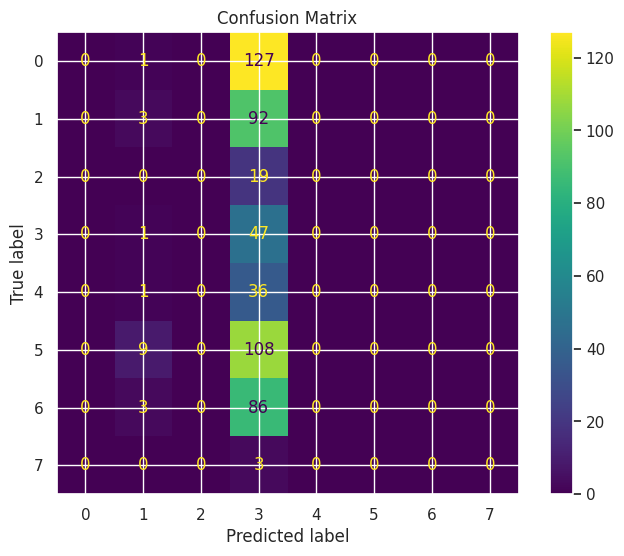

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_adam
------------------------------
TRAIN
Accuracy: 0.2490
Precision: 0.1017
Recall: 0.2490
F1: 0.1443
Kappa: 0.0562
Error Rate: 0.7510

TEST
Accuracy: 0.0933
Precision: 0.0377
Recall: 0.0933
F1: 0.0243
Kappa: 0.0009
Error Rate: 0.9067
Gap (overfitting): 0.1557

CV
Mean: 0.2157
Std: 0.0113
------------------------------
Model params:
{'num_channels': [8], 'kernel_size': 3, 'dropout': 0.0, 'dilations': [1], 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



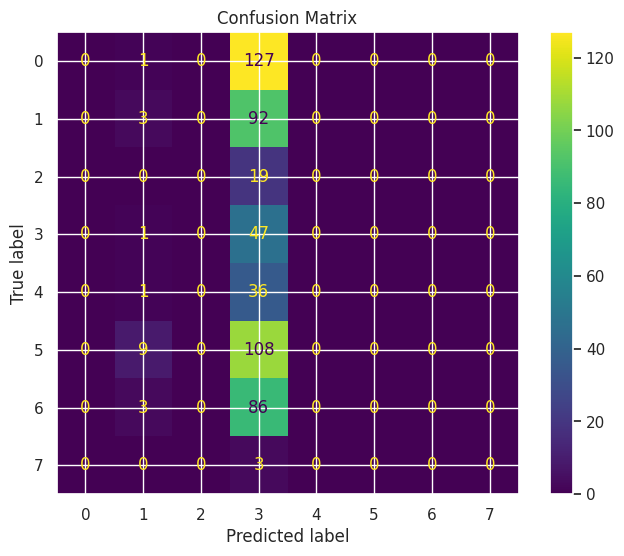

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_sgd_momentum
------------------------------
TRAIN
Accuracy: 0.2490
Precision: 0.1017
Recall: 0.2490
F1: 0.1443
Kappa: 0.0562
Error Rate: 0.7510

TEST
Accuracy: 0.0933
Precision: 0.0377
Recall: 0.0933
F1: 0.0243
Kappa: 0.0009
Error Rate: 0.9067
Gap (overfitting): 0.1557

CV
Mean: 0.2106
Std: 0.0171
------------------------------
Model params:
{'num_channels': [8], 'kernel_size': 3, 'dropout': 0.0, 'dilations': [1], 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



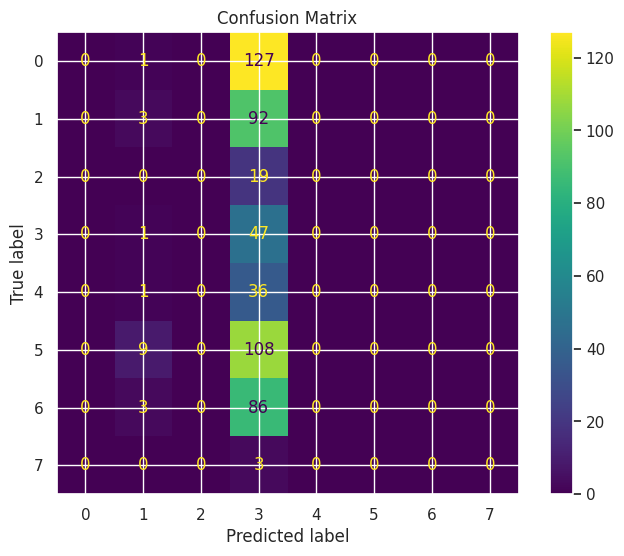

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_adam_lowLR
------------------------------
TRAIN
Accuracy: 0.2306
Precision: 0.1458
Recall: 0.2306
F1: 0.1449
Kappa: 0.0316
Error Rate: 0.7694

TEST
Accuracy: 0.2425
Precision: 0.0881
Recall: 0.2425
F1: 0.1033
Kappa: 0.0076
Error Rate: 0.7575
Gap (overfitting): -0.0120

CV
Mean: 0.2129
Std: 0.0151
------------------------------
Model params:
{'num_channels': [8], 'kernel_size': 3, 'dropout': 0.0, 'dilations': [1], 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



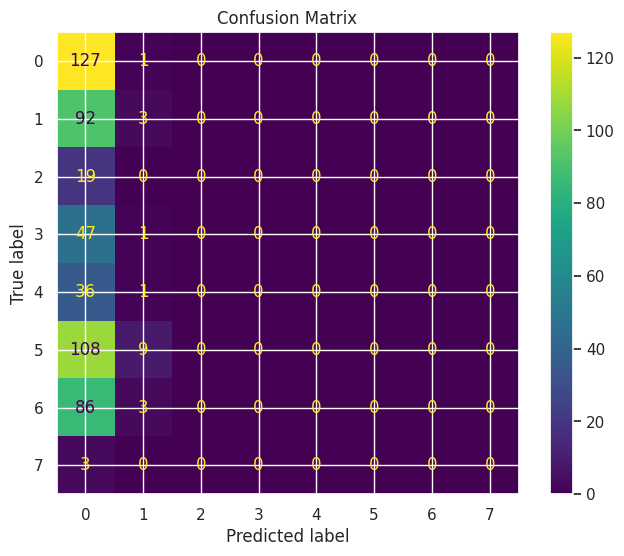

In [4]:
models_tcn = {}

# Para TCN, num_channels=[30] é o equivalente a hidden=30
models_tcn['TCN_rmsprop'] = TCNClassifier(
    num_channels=[8], kernel_size=3, dropout=0.0, dilations=[1],
    fc_hidden_layers=(),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)

models_tcn['TCN_adam'] = TCNClassifier(
    num_channels=[8], kernel_size=3, dropout=0.0, dilations=[1],
    fc_hidden_layers=(),
    solver='adam', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)

models_tcn['TCN_sgd_momentum'] = TCNClassifier(
    num_channels=[8], kernel_size=3, dropout=0.0, dilations=[1],
    fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)

models_tcn['TCN_adam_lowLR'] = TCNClassifier(
    num_channels=[8], kernel_size=3, dropout=0.0, dilations=[1],
    fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)

main(models_tcn, "tcn_experiments")

/tmp/ipykernel_12208/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(r


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_sgd_30
------------------------------
TRAIN
Accuracy: 0.2642
Precision: 0.1129
Recall: 0.2642
F1: 0.1581
Kappa: 0.0642
Error Rate: 0.7358

TEST
Accuracy: 0.1119
Precision: 0.0125
Recall: 0.1119
F1: 0.0225
Kappa: 0.0000
Error Rate: 0.8881
Gap (overfitting): 0.1523

CV
Mean: 0.2616
Std: 0.0090
------------------------------
Model params:
{'num_channels': [8], 'kernel_size': 3, 'dropout': 0.0, 'dilations': [1], 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



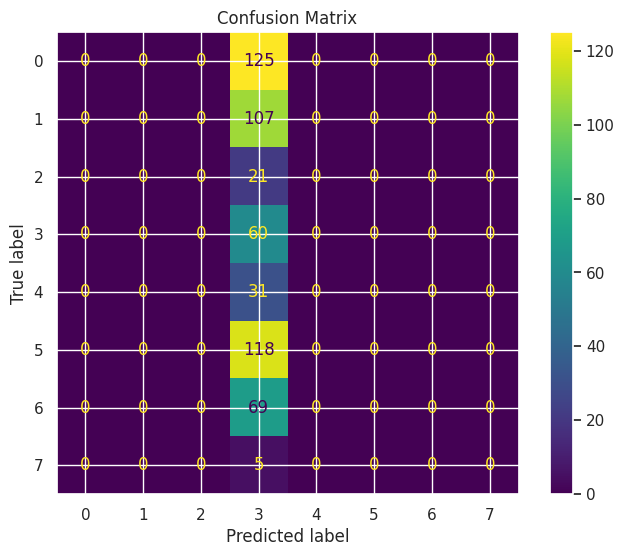

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_sgd_50
------------------------------
TRAIN
Accuracy: 0.2698
Precision: 0.1151
Recall: 0.2698
F1: 0.1613
Kappa: 0.0713
Error Rate: 0.7302

TEST
Accuracy: 0.1119
Precision: 0.0125
Recall: 0.1119
F1: 0.0225
Kappa: 0.0000
Error Rate: 0.8881
Gap (overfitting): 0.1579

CV
Mean: 0.2594
Std: 0.0046
------------------------------
Model params:
{'num_channels': [16], 'kernel_size': 3, 'dropout': 0.0, 'dilations': [1], 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



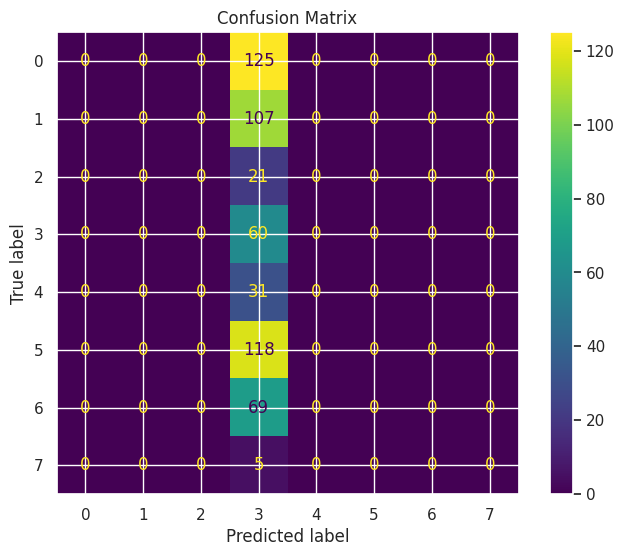

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_sgd_508
------------------------------
TRAIN
Accuracy: 0.3939
Precision: 0.4384
Recall: 0.3939
F1: 0.3759
Kappa: 0.2618
Error Rate: 0.6061

TEST
Accuracy: 0.1026
Precision: 0.0388
Recall: 0.1026
F1: 0.0324
Kappa: -0.0176
Error Rate: 0.8974
Gap (overfitting): 0.2913

CV
Mean: 0.4930
Std: 0.0510
------------------------------
Model params:
{'num_channels': [16, 8, 8], 'kernel_size': 3, 'dropout': 0.0, 'dilations': [1, 2, 4], 'fc_hidden_layers': (8,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



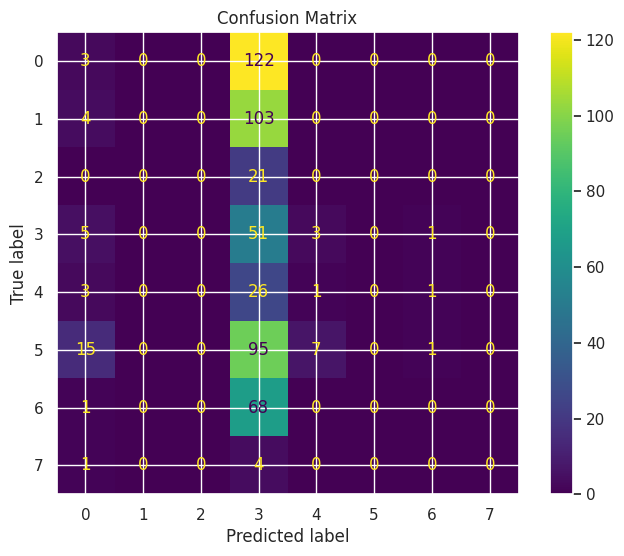

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_sgd1e3
------------------------------
TRAIN
Accuracy: 0.2698
Precision: 0.1151
Recall: 0.2698
F1: 0.1613
Kappa: 0.0713
Error Rate: 0.7302

TEST
Accuracy: 0.1119
Precision: 0.0125
Recall: 0.1119
F1: 0.0225
Kappa: 0.0000
Error Rate: 0.8881
Gap (overfitting): 0.1579

CV
Mean: 0.2594
Std: 0.0046
------------------------------
Model params:
{'num_channels': [16], 'kernel_size': 3, 'dropout': 0.3, 'dilations': [1], 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



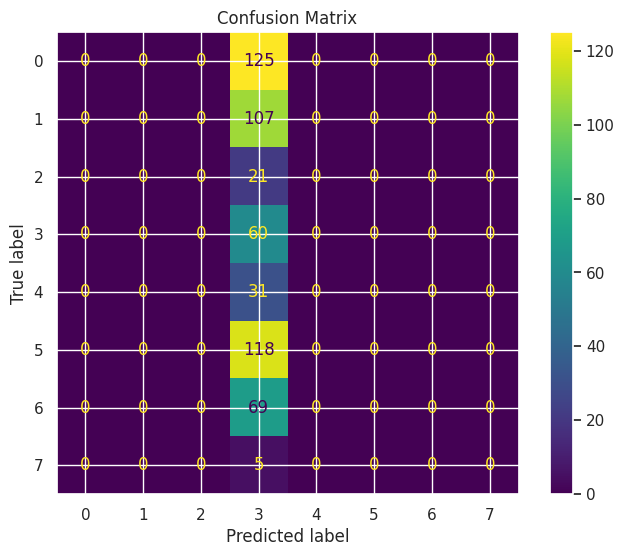

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCNrop_30
------------------------------
TRAIN
Accuracy: 0.2826
Precision: 0.1721
Recall: 0.2826
F1: 0.1900
Kappa: 0.0920
Error Rate: 0.7174

TEST
Accuracy: 0.1119
Precision: 0.0125
Recall: 0.1119
F1: 0.0225
Kappa: 0.0000
Error Rate: 0.8881
Gap (overfitting): 0.1707

CV
Mean: 0.2549
Std: 0.0035
------------------------------
Model params:
{'num_channels': [8], 'kernel_size': 3, 'dropout': 0.0, 'dilations': [1], 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



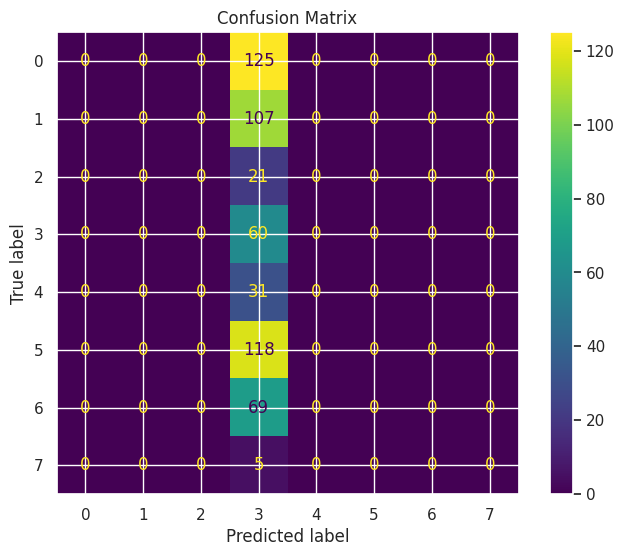

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCNrop_50
------------------------------
TRAIN
Accuracy: 0.2722
Precision: 0.1691
Recall: 0.2722
F1: 0.1737
Kappa: 0.0763
Error Rate: 0.7278

TEST
Accuracy: 0.1119
Precision: 0.0125
Recall: 0.1119
F1: 0.0225
Kappa: 0.0000
Error Rate: 0.8881
Gap (overfitting): 0.1603

CV
Mean: 0.2633
Std: 0.0097
------------------------------
Model params:
{'num_channels': [16], 'kernel_size': 3, 'dropout': 0.0, 'dilations': [1], 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



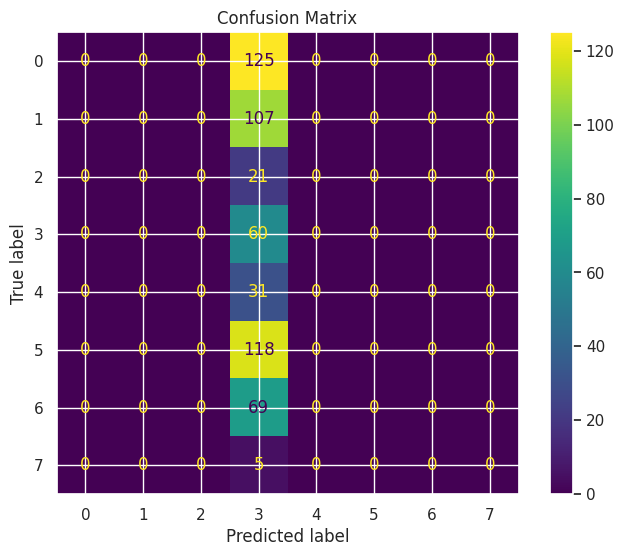

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCNrop_50_8
------------------------------
TRAIN
Accuracy: 0.5508
Precision: 0.5959
Recall: 0.5508
F1: 0.5398
Kappa: 0.4504
Error Rate: 0.4492

TEST
Accuracy: 0.0243
Precision: 0.0636
Recall: 0.0243
F1: 0.0239
Kappa: -0.0081
Error Rate: 0.9757
Gap (overfitting): 0.5266

CV
Mean: 0.6134
Std: 0.0940
------------------------------
Model params:
{'num_channels': [16, 8, 8], 'kernel_size': 3, 'dropout': 0.0, 'dilations': [1, 2, 4], 'fc_hidden_layers': (8,), 'input_size': 21, 'output_size': 8, 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



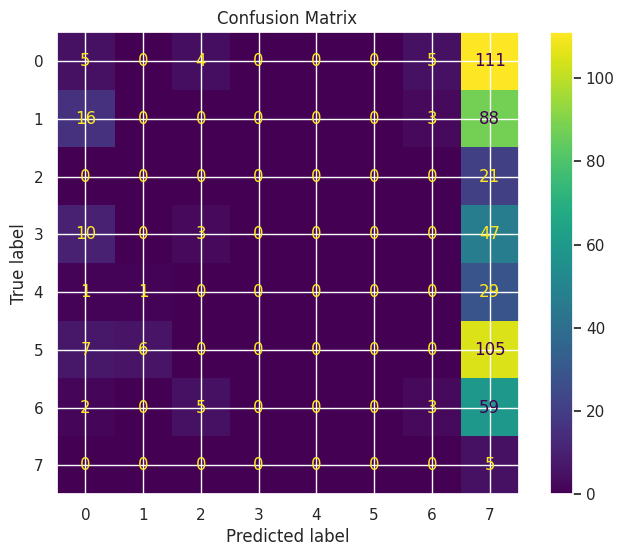

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_low30
------------------------------
TRAIN
Accuracy: 0.2682
Precision: 0.1143
Recall: 0.2682
F1: 0.1602
Kappa: 0.0693
Error Rate: 0.7318

TEST
Accuracy: 0.1119
Precision: 0.0126
Recall: 0.1119
F1: 0.0226
Kappa: -0.0003
Error Rate: 0.8881
Gap (overfitting): 0.1563

CV
Mean: 0.2633
Std: 0.0071
------------------------------
Model params:
{'num_channels': [8], 'kernel_size': 3, 'dropout': 0.0, 'dilations': [1], 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



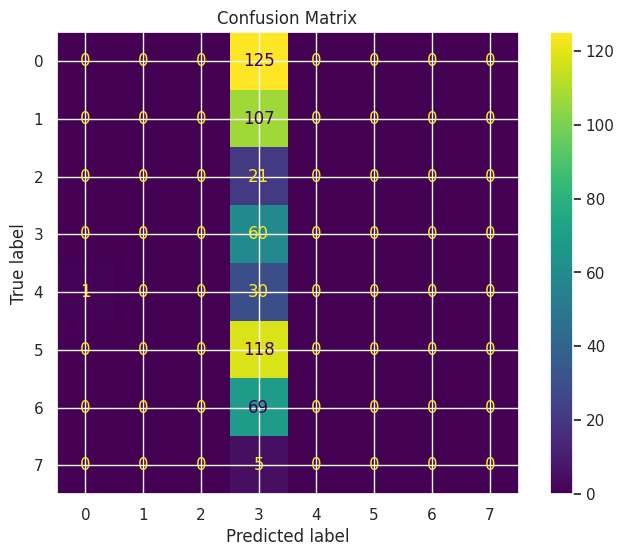

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCNlowL50
------------------------------
TRAIN
Accuracy: 0.2682
Precision: 0.1140
Recall: 0.2682
F1: 0.1598
Kappa: 0.0693
Error Rate: 0.7318

TEST
Accuracy: 0.1119
Precision: 0.0126
Recall: 0.1119
F1: 0.0226
Kappa: -0.0003
Error Rate: 0.8881
Gap (overfitting): 0.1563

CV
Mean: 0.2616
Std: 0.0082
------------------------------
Model params:
{'num_channels': [16], 'kernel_size': 3, 'dropout': 0.0, 'dilations': [1], 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



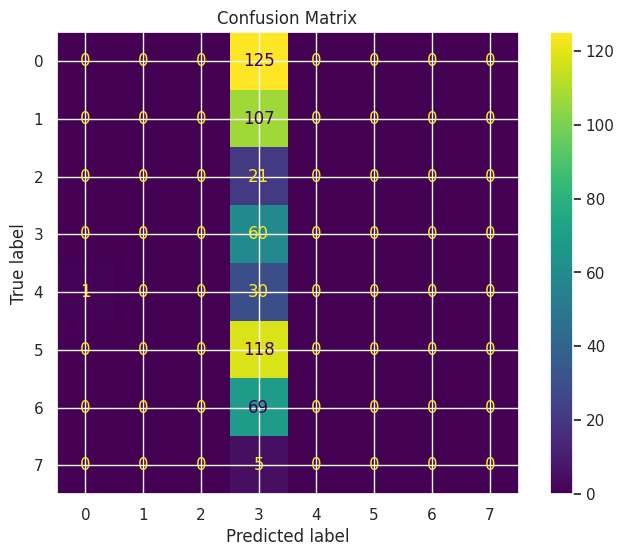

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_low50_8
------------------------------
TRAIN
Accuracy: 0.4211
Precision: 0.4061
Recall: 0.4211
F1: 0.3907
Kappa: 0.2789
Error Rate: 0.5789

TEST
Accuracy: 0.1138
Precision: 0.0850
Recall: 0.1138
F1: 0.0545
Kappa: -0.0083
Error Rate: 0.8862
Gap (overfitting): 0.3073

CV
Mean: 0.3608
Std: 0.0452
------------------------------
Model params:
{'num_channels': [16, 8, 8], 'kernel_size': 3, 'dropout': 0.0, 'dilations': [1, 2, 4], 'fc_hidden_layers': (8,), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



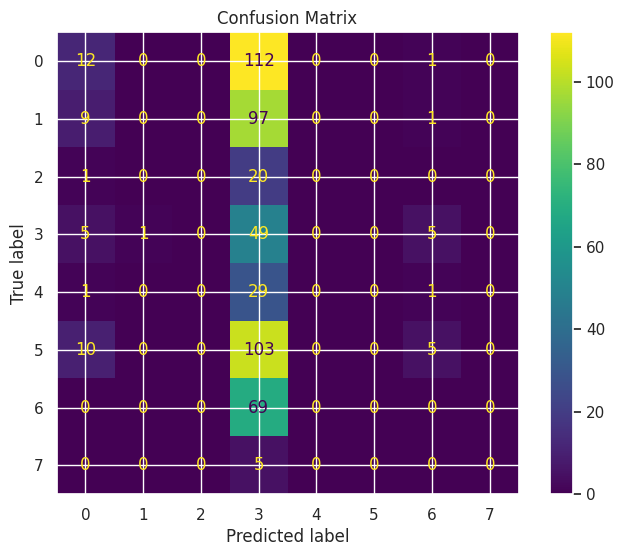

In [5]:
models_tcn_f1 = {}


# ============================================================
# 1º MELHOR: TCN_sgd_momentum
# ============================================================


models_tcn_f1['TCN_sgd_30'] = TCNClassifier(
    num_channels=[8], kernel_size=3, dropout=0.0, dilations=[1],
    fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_tcn_f1['TCN_sgd_50'] = TCNClassifier(
    num_channels=[16], kernel_size=3, dropout=0.0, dilations=[1],
    fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


# 3 camadas TCN com dilations diferentes (equivalente a 50_8)
models_tcn_f1['TCN_sgd_508'] = TCNClassifier(
    num_channels=[16, 8, 8], kernel_size=3, dropout=0.0, dilations=[1, 2, 4],
    fc_hidden_layers=(8,),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


# Regularização
models_tcn_f1['TCN_sgd1e3'] = TCNClassifier(
    num_channels=[16], kernel_size=3, dropout=0.3, dilations=[1],
    fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# 2º MELHOR: TCN_rmsprop
# ============================================================


models_tcn_f1['TCNrop_30'] = TCNClassifier(
    num_channels=[8], kernel_size=3, dropout=0.0, dilations=[1],
    fc_hidden_layers=(),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)


models_tcn_f1['TCNrop_50'] = TCNClassifier(
    num_channels=[16], kernel_size=3, dropout=0.0, dilations=[1],
    fc_hidden_layers=(),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)


models_tcn_f1['TCNrop_50_8'] = TCNClassifier(
    num_channels=[16, 8, 8], kernel_size=3, dropout=0.0, dilations=[1, 2, 4],
    fc_hidden_layers=(8,),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# 3º MELHOR: TCN_adam_lowLR
# ============================================================


models_tcn_f1['TCN_low30'] = TCNClassifier(
    num_channels=[8], kernel_size=3, dropout=0.0, dilations=[1],
    fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_tcn_f1['TCNlowL50'] = TCNClassifier(
    num_channels=[16], kernel_size=3, dropout=0.0, dilations=[1],
    fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_tcn_f1['TCN_low50_8'] = TCNClassifier(
    num_channels=[16, 8, 8], kernel_size=3, dropout=0.0, dilations=[1, 2, 4],
    fc_hidden_layers=(8,),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


main(models_tcn_f1, "tcn_fase_1")



/tmp/ipykernel_12208/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(r


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TC_adam
------------------------------
TRAIN
Accuracy: 0.2266
Precision: 0.1039
Recall: 0.2266
F1: 0.1367
Kappa: 0.0099
Error Rate: 0.7734

TEST
Accuracy: 0.1437
Precision: 0.0706
Recall: 0.1437
F1: 0.0763
Kappa: -0.0084
Error Rate: 0.8563
Gap (overfitting): 0.0829

CV
Mean: 0.2252
Std: 0.0133
------------------------------
Model params:
{'num_channels': [8], 'kernel_size': 3, 'dropout': 0.0, 'dilations': [1], 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



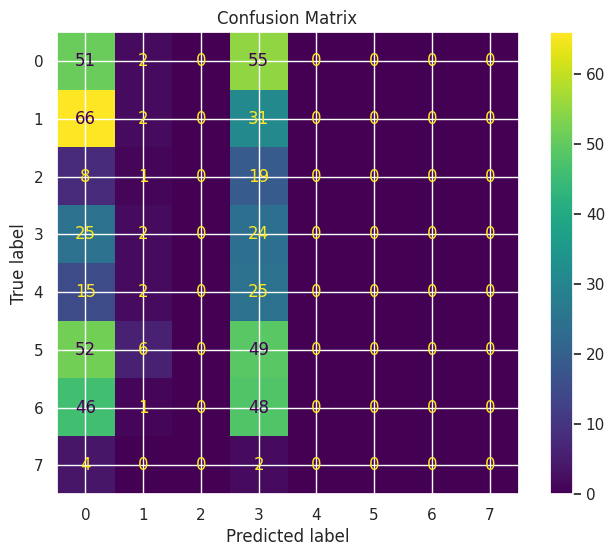

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_sgd
------------------------------
TRAIN
Accuracy: 0.2418
Precision: 0.1031
Recall: 0.2418
F1: 0.1443
Kappa: 0.0317
Error Rate: 0.7582

TEST
Accuracy: 0.0933
Precision: 0.0319
Recall: 0.0933
F1: 0.0225
Kappa: -0.0057
Error Rate: 0.9067
Gap (overfitting): 0.1485

CV
Mean: 0.2336
Std: 0.0157
------------------------------
Model params:
{'num_channels': [8], 'kernel_size': 3, 'dropout': 0.0, 'dilations': [1], 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



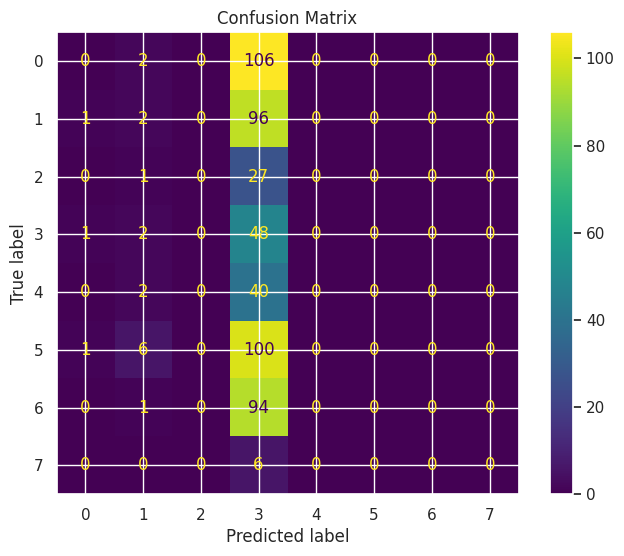

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCrmsprop
------------------------------
TRAIN
Accuracy: 0.2386
Precision: 0.1016
Recall: 0.2386
F1: 0.1420
Kappa: 0.0267
Error Rate: 0.7614

TEST
Accuracy: 0.0933
Precision: 0.0319
Recall: 0.0933
F1: 0.0225
Kappa: -0.0055
Error Rate: 0.9067
Gap (overfitting): 0.1453

CV
Mean: 0.2241
Std: 0.0099
------------------------------
Model params:
{'num_channels': [8], 'kernel_size': 3, 'dropout': 0.0, 'dilations': [1], 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



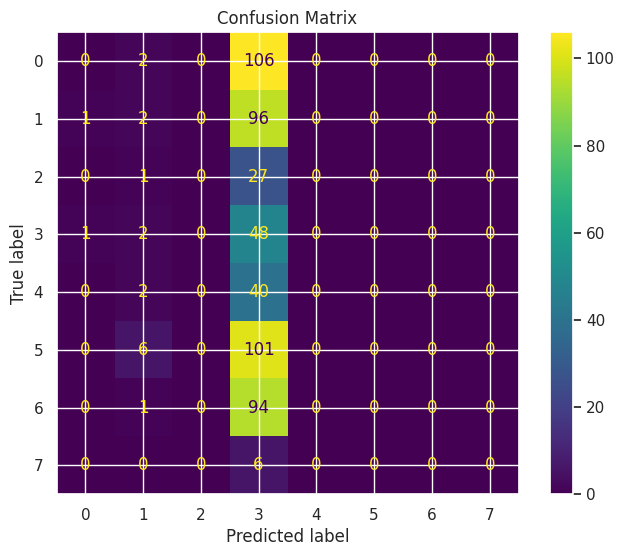

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN30
------------------------------
TRAIN
Accuracy: 0.2266
Precision: 0.1039
Recall: 0.2266
F1: 0.1367
Kappa: 0.0099
Error Rate: 0.7734

TEST
Accuracy: 0.1437
Precision: 0.0706
Recall: 0.1437
F1: 0.0763
Kappa: -0.0084
Error Rate: 0.8563
Gap (overfitting): 0.0829

CV
Mean: 0.2252
Std: 0.0133
------------------------------
Model params:
{'num_channels': [8], 'kernel_size': 3, 'dropout': 0.0, 'dilations': [1], 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



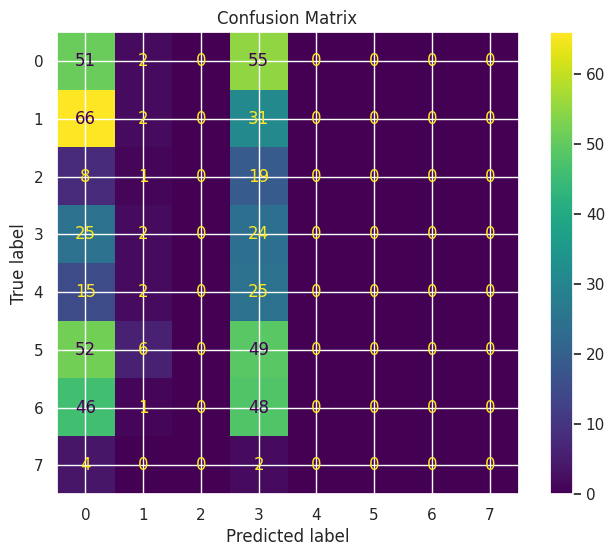

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_50
------------------------------
TRAIN
Accuracy: 0.2154
Precision: 0.1128
Recall: 0.2154
F1: 0.1435
Kappa: -0.0024
Error Rate: 0.7846

TEST
Accuracy: 0.0896
Precision: 0.0603
Recall: 0.0896
F1: 0.0429
Kappa: -0.0245
Error Rate: 0.9104
Gap (overfitting): 0.1258

CV
Mean: 0.2241
Std: 0.0121
------------------------------
Model params:
{'num_channels': [16], 'kernel_size': 3, 'dropout': 0.0, 'dilations': [1], 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



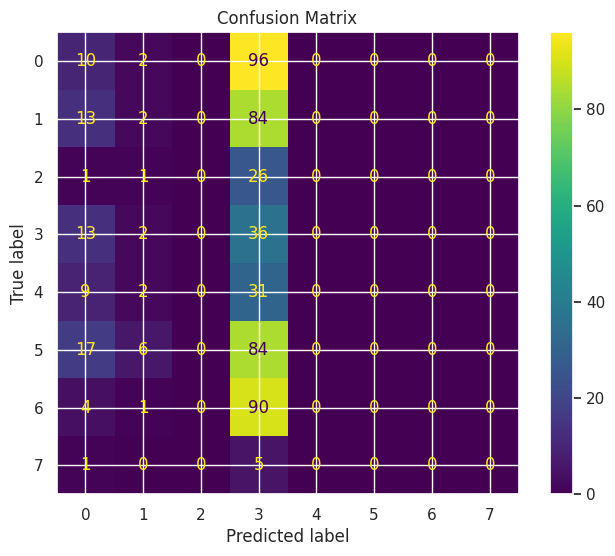

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_50_8
------------------------------
TRAIN
Accuracy: 0.3667
Precision: 0.3313
Recall: 0.3667
F1: 0.3179
Kappa: 0.2129
Error Rate: 0.6333

TEST
Accuracy: 0.2034
Precision: 0.0669
Recall: 0.2034
F1: 0.0810
Kappa: 0.0052
Error Rate: 0.7966
Gap (overfitting): 0.1633

CV
Mean: 0.3972
Std: 0.0359
------------------------------
Model params:
{'num_channels': [16, 8, 8], 'kernel_size': 3, 'dropout': 0.0, 'dilations': [1, 2, 4], 'fc_hidden_layers': (8,), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



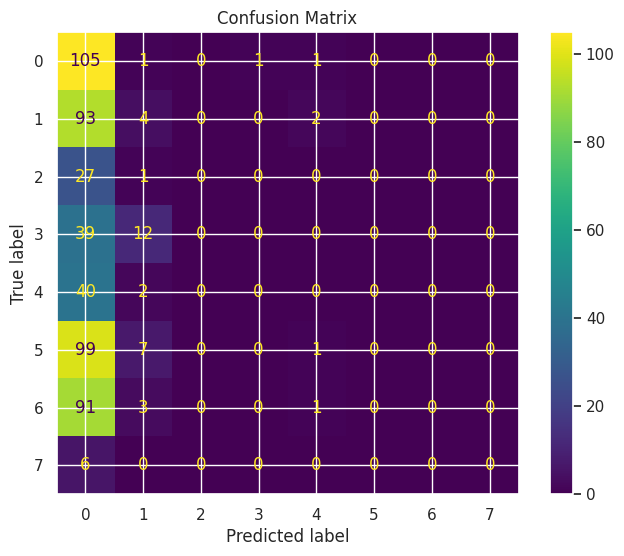

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TC_0
------------------------------
TRAIN
Accuracy: 0.2266
Precision: 0.1039
Recall: 0.2266
F1: 0.1367
Kappa: 0.0099
Error Rate: 0.7734

TEST
Accuracy: 0.1437
Precision: 0.0706
Recall: 0.1437
F1: 0.0763
Kappa: -0.0084
Error Rate: 0.8563
Gap (overfitting): 0.0829

CV
Mean: 0.2252
Std: 0.0133
------------------------------
Model params:
{'num_channels': [8], 'kernel_size': 3, 'dropout': 0.0, 'dilations': [1], 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



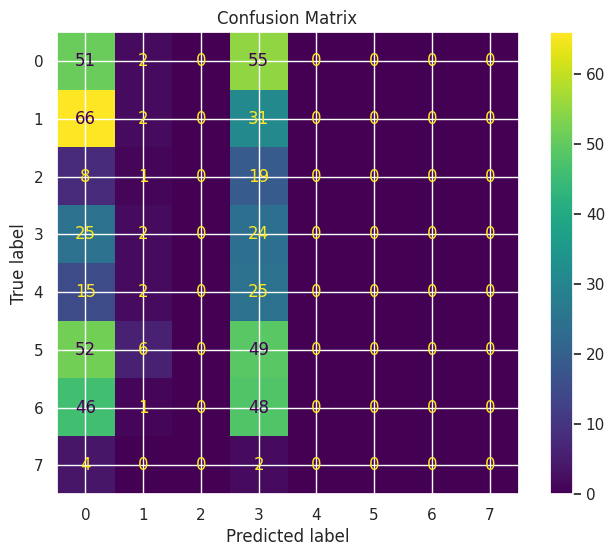

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TC1e-1
------------------------------
TRAIN
Accuracy: 0.2266
Precision: 0.1039
Recall: 0.2266
F1: 0.1367
Kappa: 0.0099
Error Rate: 0.7734

TEST
Accuracy: 0.1437
Precision: 0.0706
Recall: 0.1437
F1: 0.0763
Kappa: -0.0084
Error Rate: 0.8563
Gap (overfitting): 0.0829

CV
Mean: 0.2252
Std: 0.0133
------------------------------
Model params:
{'num_channels': [8], 'kernel_size': 3, 'dropout': 0.1, 'dilations': [1], 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



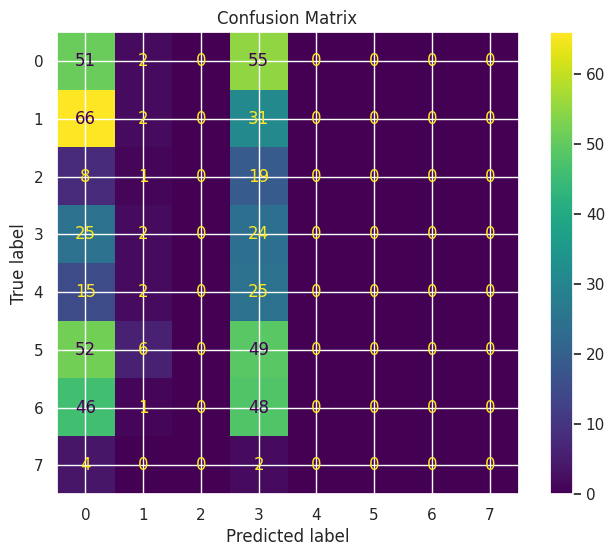

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_DF1
------------------------------
TRAIN
Accuracy: 0.2610
Precision: 0.3331
Recall: 0.2610
F1: 0.2346
Kappa: 0.0689
Error Rate: 0.7390

TEST
Accuracy: 0.1045
Precision: 0.0987
Recall: 0.1045
F1: 0.0798
Kappa: -0.0292
Error Rate: 0.8955
Gap (overfitting): 0.1565

CV
Mean: 0.2627
Std: 0.0129
------------------------------
Model params:
{'num_channels': [8, 30], 'kernel_size': 3, 'dropout': 0.0, 'dilations': [1], 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



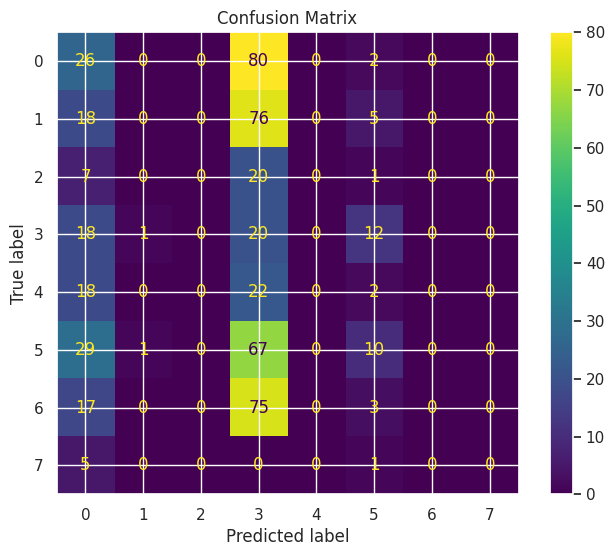

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: TCN_d_2
------------------------------
TRAIN
Accuracy: 0.6629
Precision: 0.6659
Recall: 0.6629
F1: 0.6503
Kappa: 0.5857
Error Rate: 0.3371

TEST
Accuracy: 0.2015
Precision: 0.1293
Recall: 0.2015
F1: 0.1261
Kappa: 0.0019
Error Rate: 0.7985
Gap (overfitting): 0.4614

CV
Mean: 0.6420
Std: 0.0865
------------------------------
Model params:
{'num_channels': [8, 30, 30], 'kernel_size': 3, 'dropout': 0.0, 'dilations': [1, 2], 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



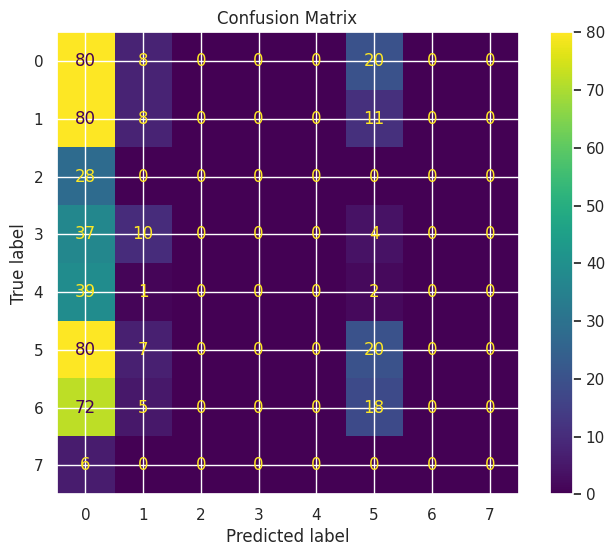

In [6]:
models_tcn_f2 = {}


# ============================================================
# OTIMIZADORES
# ============================================================


models_tcn_f2['TC_adam'] = TCNClassifier(
    num_channels=[8], kernel_size=3, dropout=0.0, dilations=[1],
    fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_tcn_f2['TCN_sgd'] = TCNClassifier(
    num_channels=[8], kernel_size=3, dropout=0.0, dilations=[1],
    fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_tcn_f2['TCrmsprop'] = TCNClassifier(
    num_channels=[8], kernel_size=3, dropout=0.0, dilations=[1],
    fc_hidden_layers=(),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# ARQUITETURAS (diferentes num_channels)
# ============================================================


# equivalente a hidden=30
models_tcn_f2['TCN30'] = TCNClassifier(
    num_channels=[8], kernel_size=3, dropout=0.0, dilations=[1],
    fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


# equivalente a hidden=50
models_tcn_f2['TCN_50'] = TCNClassifier(
    num_channels=[16], kernel_size=3, dropout=0.0, dilations=[1],
    fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


# 3 camadas TCN com dilations (equivalente a 50_8)
models_tcn_f2['TCN_50_8'] = TCNClassifier(
    num_channels=[16, 8, 8], kernel_size=3, dropout=0.0, dilations=[1, 2, 4],
    fc_hidden_layers=(8,),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# REGULARIZAÇÃO
# ============================================================


models_tcn_f2['TC_0'] = TCNClassifier(
    num_channels=[8], kernel_size=3, dropout=0.0, dilations=[1],
    fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_tcn_f2['TC1e-1'] = TCNClassifier(
    num_channels=[8], kernel_size=3, dropout=0.1, dilations=[1],
    fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# DILATIONS (equivalente a profundidade)
# ============================================================


# uma dilação
models_tcn_f2['TCN_DF1'] = TCNClassifier(
    num_channels=[8, 30], kernel_size=3, dropout=0.0, dilations=[1],
    fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


# duas dilacões
models_tcn_f2['TCN_d_2'] = TCNClassifier(
    num_channels=[8, 30, 30], kernel_size=3, dropout=0.0, dilations=[1, 2],
    fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)



main(models_tcn_f2, "tcn_fase_2")



/tmp/ipykernel_12208/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(r


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_8_sgd
------------------------------
TRAIN
Accuracy: 0.2362
Precision: 0.1406
Recall: 0.2362
F1: 0.1660
Kappa: 0.0366
Error Rate: 0.7638

TEST
Accuracy: 0.1026
Precision: 0.0291
Recall: 0.1026
F1: 0.0232
Kappa: -0.0070
Error Rate: 0.8974
Gap (overfitting): 0.1336

CV
Mean: 0.2370
Std: 0.0098
------------------------------
Model params:
{'num_channels': [8], 'kernel_size': 3, 'dropout': 0.0, 'dilations': [1], 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



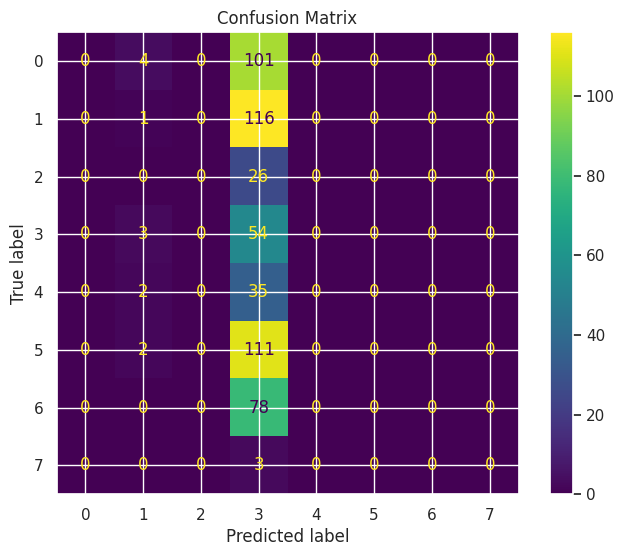

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_8_sgd_95
------------------------------
TRAIN
Accuracy: 0.2330
Precision: 0.1758
Recall: 0.2330
F1: 0.1612
Kappa: 0.0347
Error Rate: 0.7670

TEST
Accuracy: 0.1026
Precision: 0.0291
Recall: 0.1026
F1: 0.0232
Kappa: -0.0070
Error Rate: 0.8974
Gap (overfitting): 0.1304

CV
Mean: 0.2420
Std: 0.0091
------------------------------
Model params:
{'num_channels': [8], 'kernel_size': 3, 'dropout': 0.0, 'dilations': [1], 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.95, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



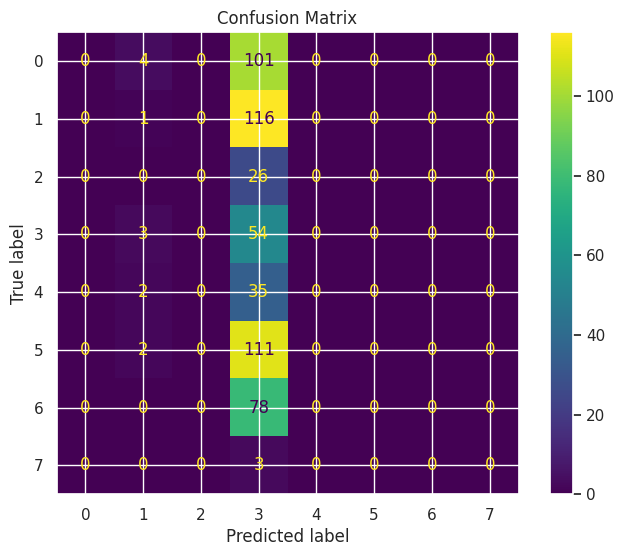

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_sgd
------------------------------
TRAIN
Accuracy: 0.2154
Precision: 0.1340
Recall: 0.2154
F1: 0.1649
Kappa: 0.0073
Error Rate: 0.7846

TEST
Accuracy: 0.1026
Precision: 0.0291
Recall: 0.1026
F1: 0.0232
Kappa: -0.0070
Error Rate: 0.8974
Gap (overfitting): 0.1128

CV
Mean: 0.2308
Std: 0.0121
------------------------------
Model params:
{'num_channels': [16], 'kernel_size': 3, 'dropout': 0.0, 'dilations': [1], 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



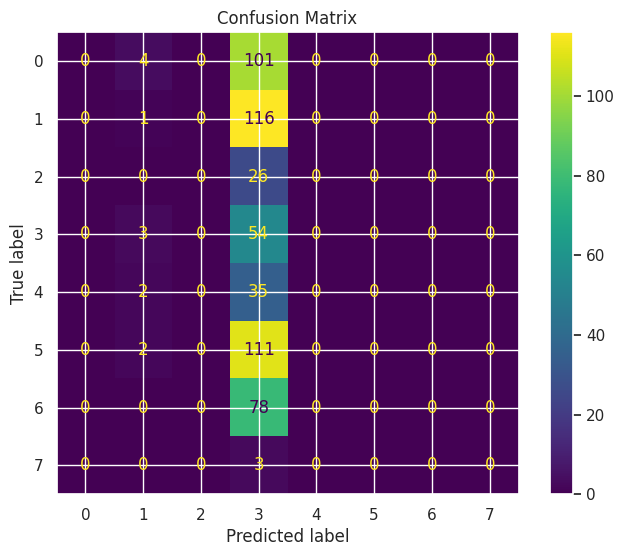

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_sgd_95
------------------------------
TRAIN
Accuracy: 0.2194
Precision: 0.1795
Recall: 0.2194
F1: 0.1840
Kappa: 0.0161
Error Rate: 0.7806

TEST
Accuracy: 0.1026
Precision: 0.0291
Recall: 0.1026
F1: 0.0232
Kappa: -0.0070
Error Rate: 0.8974
Gap (overfitting): 0.1168

CV
Mean: 0.2359
Std: 0.0194
------------------------------
Model params:
{'num_channels': [16], 'kernel_size': 3, 'dropout': 0.0, 'dilations': [1], 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.95, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



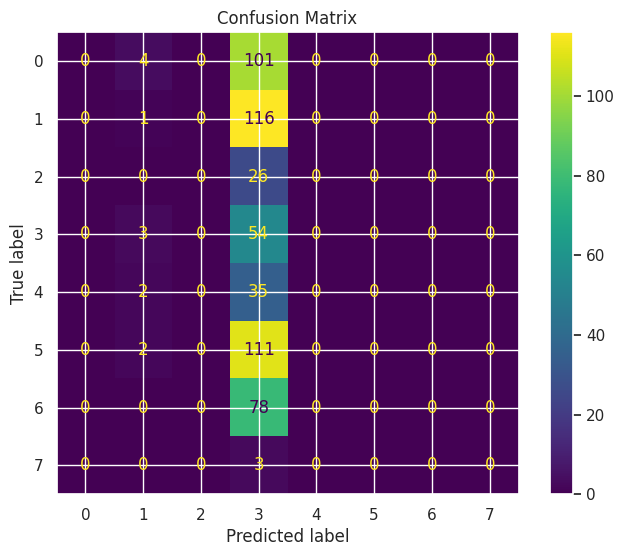

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_508sgd
------------------------------
TRAIN
Accuracy: 0.5420
Precision: 0.5719
Recall: 0.5420
F1: 0.5232
Kappa: 0.4321
Error Rate: 0.4580

TEST
Accuracy: 0.1978
Precision: 0.1220
Recall: 0.1978
F1: 0.1268
Kappa: -0.0152
Error Rate: 0.8022
Gap (overfitting): 0.3443

CV
Mean: 0.4852
Std: 0.0420
------------------------------
Model params:
{'num_channels': [16, 8, 8], 'kernel_size': 3, 'dropout': 0.0, 'dilations': [1, 2, 4], 'fc_hidden_layers': (8,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



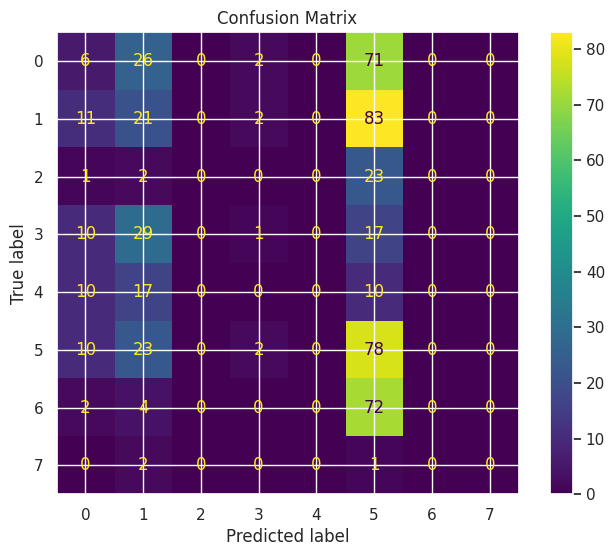

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_8sgd95
------------------------------
TRAIN
Accuracy: 0.6853
Precision: 0.7165
Recall: 0.6853
F1: 0.6694
Kappa: 0.6143
Error Rate: 0.3147

TEST
Accuracy: 0.2108
Precision: 0.0444
Recall: 0.2108
F1: 0.0734
Kappa: 0.0000
Error Rate: 0.7892
Gap (overfitting): 0.4745

CV
Mean: 0.5417
Std: 0.0916
------------------------------
Model params:
{'num_channels': [16, 8, 8], 'kernel_size': 3, 'dropout': 0.0, 'dilations': [1, 2, 4], 'fc_hidden_layers': (8,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.95, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



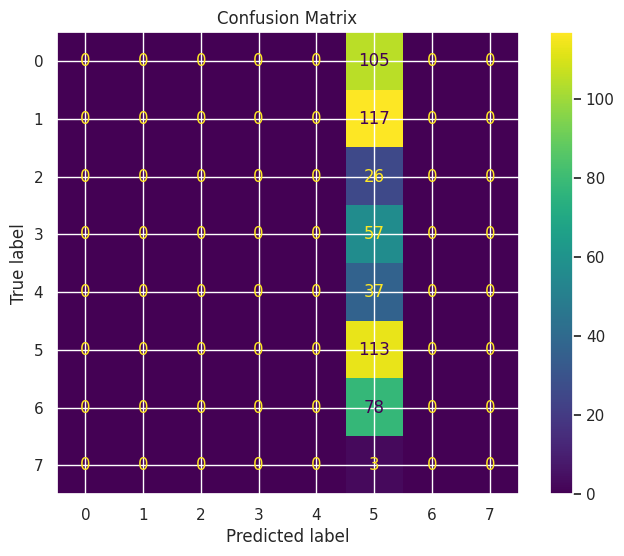

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_8_g1e-4
------------------------------
TRAIN
Accuracy: 0.2090
Precision: 0.1319
Recall: 0.2090
F1: 0.1616
Kappa: -0.0013
Error Rate: 0.7910

TEST
Accuracy: 0.1026
Precision: 0.0292
Recall: 0.1026
F1: 0.0232
Kappa: -0.0072
Error Rate: 0.8974
Gap (overfitting): 0.1064

CV
Mean: 0.2308
Std: 0.0103
------------------------------
Model params:
{'num_channels': [8], 'kernel_size': 3, 'dropout': 0.2, 'dilations': [1], 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



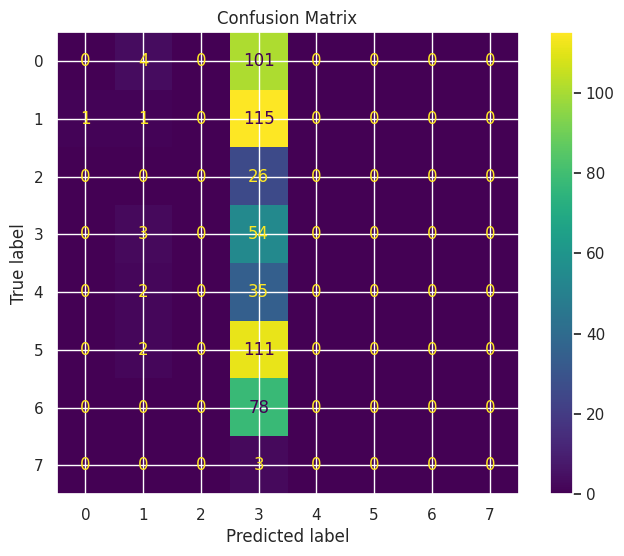

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_g1e-4
------------------------------
TRAIN
Accuracy: 0.2210
Precision: 0.1362
Recall: 0.2210
F1: 0.1671
Kappa: 0.0146
Error Rate: 0.7790

TEST
Accuracy: 0.1026
Precision: 0.0292
Recall: 0.1026
F1: 0.0232
Kappa: -0.0072
Error Rate: 0.8974
Gap (overfitting): 0.1184

CV
Mean: 0.2286
Std: 0.0121
------------------------------
Model params:
{'num_channels': [16], 'kernel_size': 3, 'dropout': 0.2, 'dilations': [1], 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



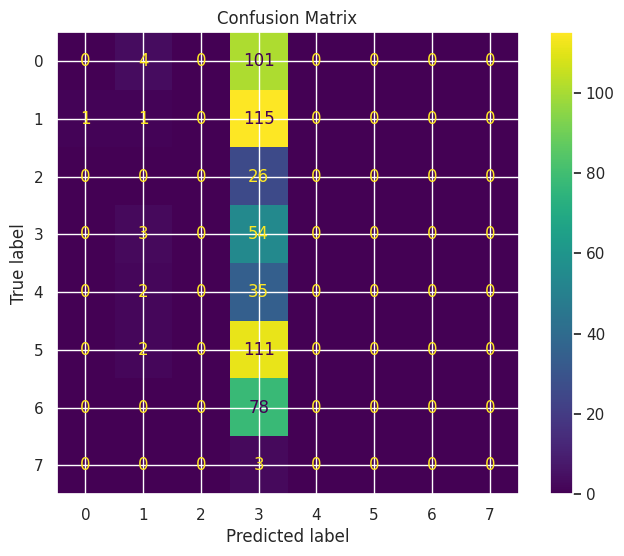

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_8_eg1e-4
------------------------------
TRAIN
Accuracy: 0.3066
Precision: 0.2249
Recall: 0.3066
F1: 0.2342
Kappa: 0.1366
Error Rate: 0.6934

TEST
Accuracy: 0.2127
Precision: 0.1214
Recall: 0.2127
F1: 0.1049
Kappa: 0.0084
Error Rate: 0.7873
Gap (overfitting): 0.0940

CV
Mean: 0.3188
Std: 0.0222
------------------------------
Model params:
{'num_channels': [16, 8, 8], 'kernel_size': 3, 'dropout': 0.2, 'dilations': [1, 2, 4], 'fc_hidden_layers': (8,), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



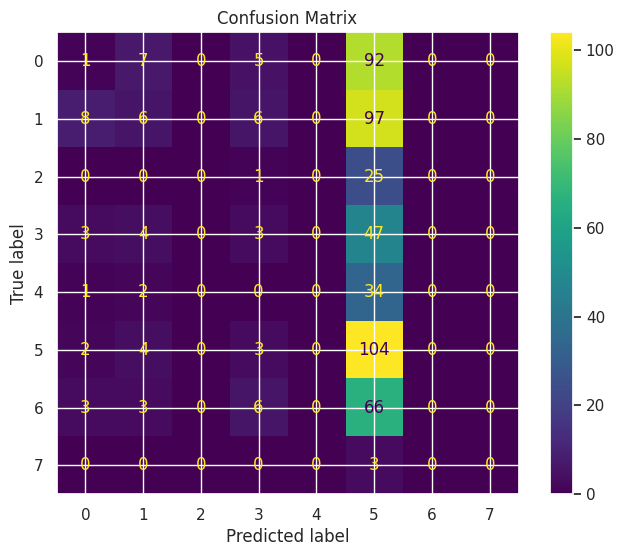

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_8_sgd_2
------------------------------
TRAIN
Accuracy: 0.2362
Precision: 0.1406
Recall: 0.2362
F1: 0.1660
Kappa: 0.0366
Error Rate: 0.7638

TEST
Accuracy: 0.1026
Precision: 0.0291
Recall: 0.1026
F1: 0.0232
Kappa: -0.0070
Error Rate: 0.8974
Gap (overfitting): 0.1336

CV
Mean: 0.2370
Std: 0.0098
------------------------------
Model params:
{'num_channels': [8], 'kernel_size': 3, 'dropout': 0.2, 'dilations': [1], 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



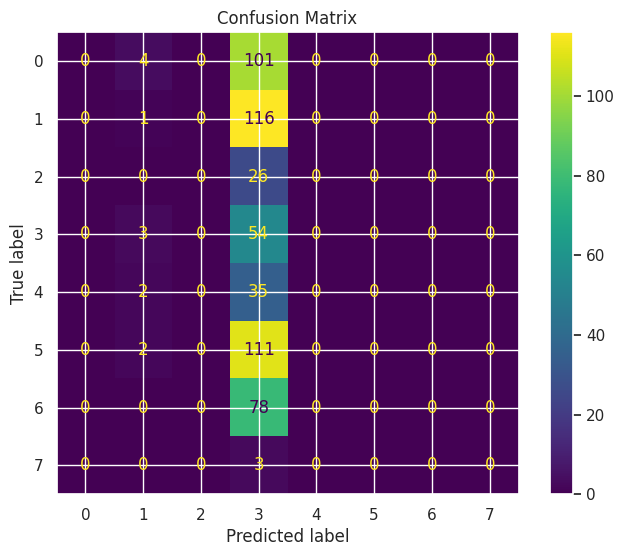

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_8_sgd_3
------------------------------
TRAIN
Accuracy: 0.2362
Precision: 0.1406
Recall: 0.2362
F1: 0.1660
Kappa: 0.0366
Error Rate: 0.7638

TEST
Accuracy: 0.1026
Precision: 0.0291
Recall: 0.1026
F1: 0.0232
Kappa: -0.0070
Error Rate: 0.8974
Gap (overfitting): 0.1336

CV
Mean: 0.2370
Std: 0.0098
------------------------------
Model params:
{'num_channels': [8], 'kernel_size': 3, 'dropout': 0.3, 'dilations': [1], 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



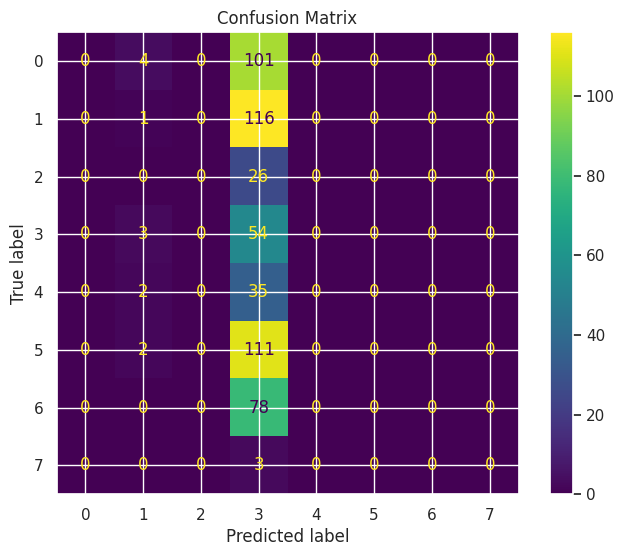

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_8sgdlowLR
------------------------------
TRAIN
Accuracy: 0.1978
Precision: 0.1318
Recall: 0.1978
F1: 0.1477
Kappa: -0.0199
Error Rate: 0.8022

TEST
Accuracy: 0.1903
Precision: 0.0559
Recall: 0.1903
F1: 0.0663
Kappa: -0.0076
Error Rate: 0.8097
Gap (overfitting): 0.0075

CV
Mean: 0.2017
Std: 0.0185
------------------------------
Model params:
{'num_channels': [8], 'kernel_size': 3, 'dropout': 0.0, 'dilations': [1], 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



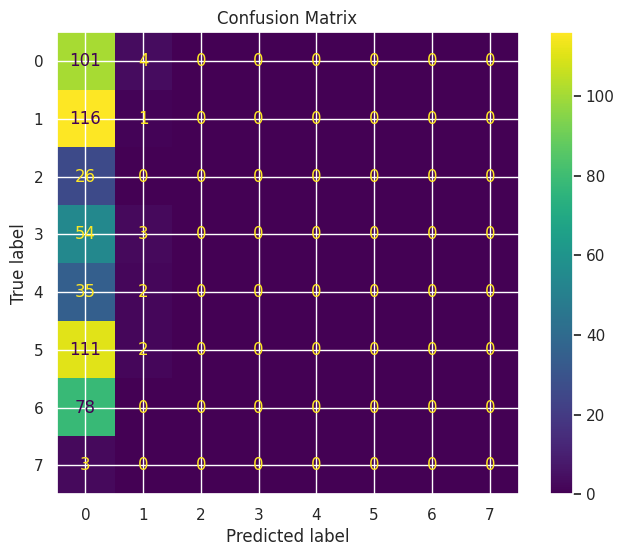

In [7]:
models_tcn_f3 = {}


# ============================================================
# 🔥 BASE TOP (SGD)
# ============================================================


models_tcn_f3['F2_8_sgd'] = TCNClassifier(
    num_channels=[8], kernel_size=3, dropout=0.0, dilations=[1],
    fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_tcn_f3['F2_8_sgd_95'] = TCNClassifier(
    num_channels=[8], kernel_size=3, dropout=0.0, dilations=[1],
    fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.95, epochs=500, batch_size=32, random_state=42
)


models_tcn_f3['F2_50_sgd'] = TCNClassifier(
    num_channels=[16], kernel_size=3, dropout=0.0, dilations=[1],
    fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_tcn_f3['F2_50_sgd_95'] = TCNClassifier(
    num_channels=[16], kernel_size=3, dropout=0.0, dilations=[1],
    fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.95, epochs=500, batch_size=32, random_state=42
)


models_tcn_f3['F2_508sgd'] = TCNClassifier(
    num_channels=[16, 8, 8], kernel_size=3, dropout=0.0, dilations=[1, 2, 4],
    fc_hidden_layers=(8,),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_tcn_f3['F2_50_8sgd95'] = TCNClassifier(
    num_channels=[16, 8, 8], kernel_size=3, dropout=0.0, dilations=[1, 2, 4],
    fc_hidden_layers=(8,),
    solver='sgd', learning_rate=0.001, momentum=0.95, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# ⚖️ CONTROLE (ADAM)
# ============================================================


models_tcn_f3['F2_8_g1e-4'] = TCNClassifier(
    num_channels=[8], kernel_size=3, dropout=0.2, dilations=[1],
    fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_tcn_f3['F2_50_g1e-4'] = TCNClassifier(
    num_channels=[16], kernel_size=3, dropout=0.2, dilations=[1],
    fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_tcn_f3['F2_50_8_eg1e-4'] = TCNClassifier(
    num_channels=[16, 8, 8], kernel_size=3, dropout=0.2, dilations=[1, 2, 4],
    fc_hidden_layers=(8,),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# 🔥 EXTRA: Regularização para SGD
# ============================================================


models_tcn_f3['F2_8_sgd_2'] = TCNClassifier(
    num_channels=[8], kernel_size=3, dropout=0.2, dilations=[1],
    fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_tcn_f3['F2_8_sgd_3'] = TCNClassifier(
    num_channels=[8], kernel_size=3, dropout=0.3, dilations=[1],
    fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_tcn_f3['F2_8sgdlowLR'] = TCNClassifier(
    num_channels=[8], kernel_size=3, dropout=0.0, dilations=[1],
    fc_hidden_layers=(),
    solver='sgd', learning_rate=0.0001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


main(models_tcn_f3, "tcn_fase_3")



/tmp/ipykernel_12208/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(r


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_8_lr1e-3_sgd
------------------------------
TRAIN
Accuracy: 0.2114
Precision: 0.1186
Recall: 0.2114
F1: 0.1481
Kappa: -0.0028
Error Rate: 0.7886

TEST
Accuracy: 0.0951
Precision: 0.0239
Recall: 0.0951
F1: 0.0199
Kappa: -0.0023
Error Rate: 0.9049
Gap (overfitting): 0.1162

CV
Mean: 0.2168
Std: 0.0193
------------------------------
Model params:
{'num_channels': [8], 'kernel_size': 3, 'dropout': 0.0, 'dilations': [1], 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



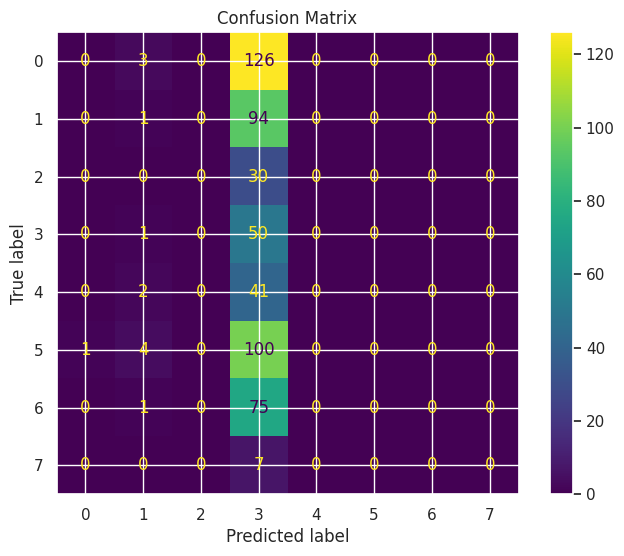

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_8_40_sgd
------------------------------
TRAIN
Accuracy: 0.2482
Precision: 0.1091
Recall: 0.2482
F1: 0.1516
Kappa: 0.0369
Error Rate: 0.7518

TEST
Accuracy: 0.2369
Precision: 0.0726
Recall: 0.2369
F1: 0.0962
Kappa: -0.0030
Error Rate: 0.7631
Gap (overfitting): 0.0113

CV
Mean: 0.2471
Std: 0.0123
------------------------------
Model params:
{'num_channels': [8], 'kernel_size': 3, 'dropout': 0.0, 'dilations': [1], 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



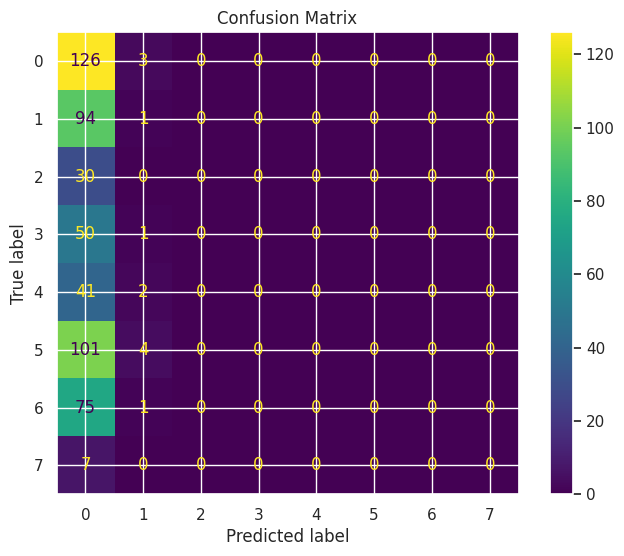

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_8_31_sgd
------------------------------
TRAIN
Accuracy: 0.2114
Precision: 0.1186
Recall: 0.2114
F1: 0.1481
Kappa: -0.0028
Error Rate: 0.7886

TEST
Accuracy: 0.0951
Precision: 0.0239
Recall: 0.0951
F1: 0.0199
Kappa: -0.0023
Error Rate: 0.9049
Gap (overfitting): 0.1162

CV
Mean: 0.2168
Std: 0.0193
------------------------------
Model params:
{'num_channels': [8], 'kernel_size': 3, 'dropout': 0.1, 'dilations': [1], 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



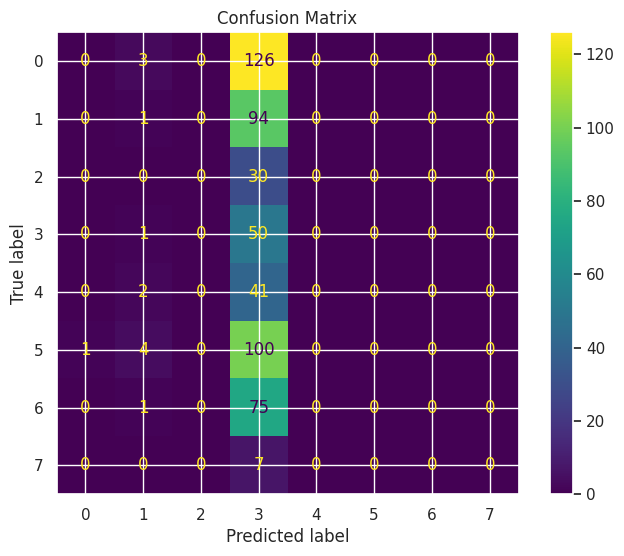

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_50_8_e-3_0_sgd
------------------------------
TRAIN
Accuracy: 0.5829
Precision: 0.6336
Recall: 0.5829
F1: 0.5545
Kappa: 0.4819
Error Rate: 0.4171

TEST
Accuracy: 0.1940
Precision: 0.1017
Recall: 0.1940
F1: 0.1018
Kappa: -0.0101
Error Rate: 0.8060
Gap (overfitting): 0.3888

CV
Mean: 0.5294
Std: 0.0679
------------------------------
Model params:
{'num_channels': [16, 8, 8], 'kernel_size': 3, 'dropout': 0.0, 'dilations': [1, 2, 4], 'fc_hidden_layers': (8,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



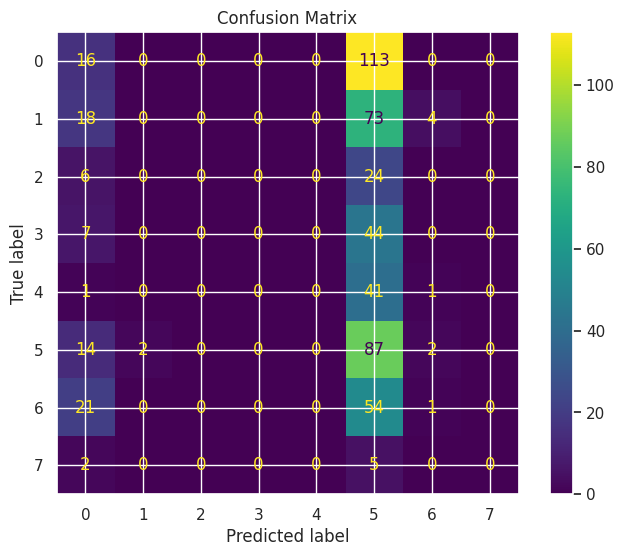

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_50_8_1e-4_0_sgd
------------------------------
TRAIN
Accuracy: 0.2962
Precision: 0.2324
Recall: 0.2962
F1: 0.2317
Kappa: 0.1145
Error Rate: 0.7038

TEST
Accuracy: 0.0970
Precision: 0.0692
Recall: 0.0970
F1: 0.0266
Kappa: -0.0026
Error Rate: 0.9030
Gap (overfitting): 0.1992

CV
Mean: 0.2734
Std: 0.0078
------------------------------
Model params:
{'num_channels': [16, 8, 8], 'kernel_size': 3, 'dropout': 0.0, 'dilations': [1, 2, 4], 'fc_hidden_layers': (8,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



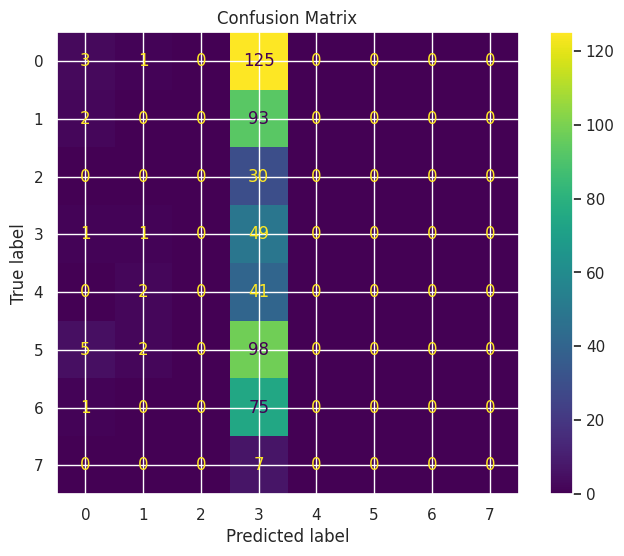

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_50_8_e-3_2_sgd
------------------------------
TRAIN
Accuracy: 0.3955
Precision: 0.3628
Recall: 0.3955
F1: 0.3708
Kappa: 0.2461
Error Rate: 0.6045

TEST
Accuracy: 0.0933
Precision: 0.0704
Recall: 0.0933
F1: 0.0385
Kappa: -0.0083
Error Rate: 0.9067
Gap (overfitting): 0.3022

CV
Mean: 0.3866
Std: 0.0149
------------------------------
Model params:
{'num_channels': [16, 8, 8], 'kernel_size': 3, 'dropout': 0.2, 'dilations': [1, 2, 4], 'fc_hidden_layers': (8,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



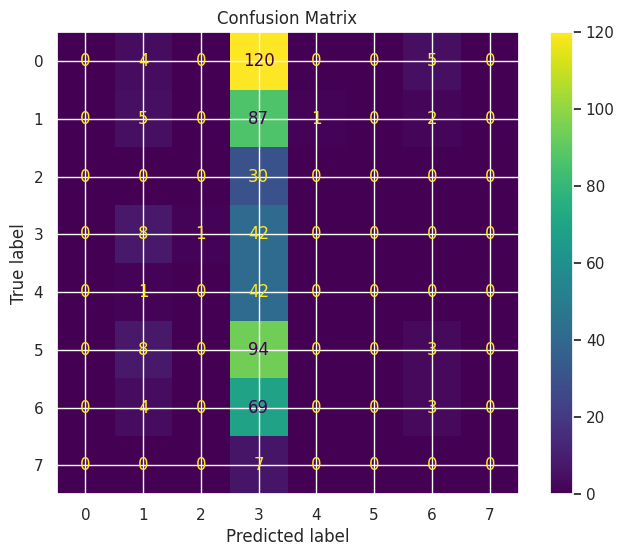

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_8_1e-42_adam
------------------------------
TRAIN
Accuracy: 0.2026
Precision: 0.1198
Recall: 0.2026
F1: 0.1483
Kappa: -0.0158
Error Rate: 0.7974

TEST
Accuracy: 0.0821
Precision: 0.2334
Recall: 0.0821
F1: 0.0243
Kappa: -0.0216
Error Rate: 0.9179
Gap (overfitting): 0.1205

CV
Mean: 0.2162
Std: 0.0210
------------------------------
Model params:
{'num_channels': [8], 'kernel_size': 3, 'dropout': 0.2, 'dilations': [1], 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



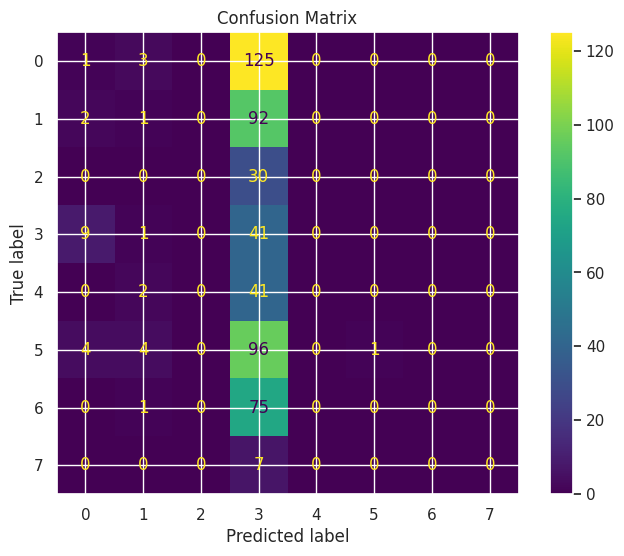

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_50_81e-42_adam
------------------------------
TRAIN
Accuracy: 0.3331
Precision: 0.3797
Recall: 0.3331
F1: 0.2606
Kappa: 0.1642
Error Rate: 0.6669

TEST
Accuracy: 0.2332
Precision: 0.2310
Recall: 0.2332
F1: 0.1310
Kappa: 0.0123
Error Rate: 0.7668
Gap (overfitting): 0.0999

CV
Mean: 0.3468
Std: 0.0145
------------------------------
Model params:
{'num_channels': [16, 8, 8], 'kernel_size': 3, 'dropout': 0.2, 'dilations': [1, 2, 4], 'fc_hidden_layers': (8,), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



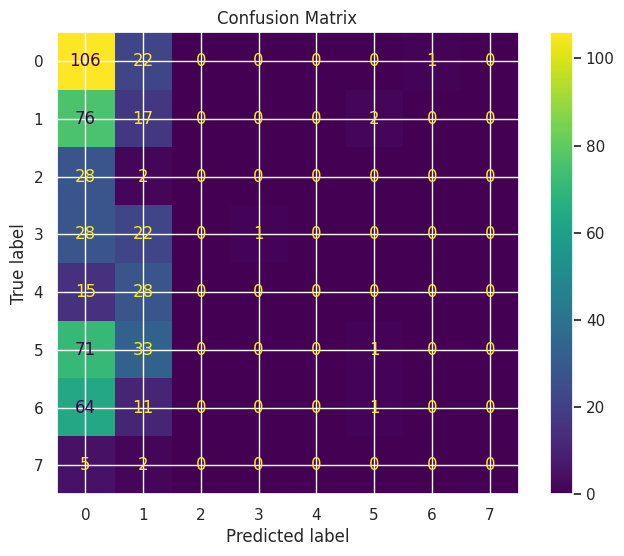

In [8]:
models_tcn_f4 = {}


# ============================================================
# 🔥 SGD com num_channels=8 (base)
# ============================================================


models_tcn_f4['F3_8_lr1e-3_sgd'] = TCNClassifier(
    num_channels=[8], kernel_size=3, dropout=0.0, dilations=[1],
    fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)




models_tcn_f4['F3_8_40_sgd'] = TCNClassifier(
    num_channels=[8], kernel_size=3, dropout=0.0, dilations=[1],
    fc_hidden_layers=(),
    solver='sgd', learning_rate=0.0001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_tcn_f4['F3_8_31_sgd'] = TCNClassifier(
    num_channels=[8], kernel_size=3, dropout=0.1, dilations=[1],
    fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)



# ============================================================
# 🔥 SGD com arquitetura 50_8 (3 camadas com dilations)
# ============================================================


models_tcn_f4['F3_50_8_e-3_0_sgd'] = TCNClassifier(
    num_channels=[16, 8, 8], kernel_size=3, dropout=0.0, dilations=[1, 2, 4],
    fc_hidden_layers=(8,),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_tcn_f4['F3_50_8_1e-4_0_sgd'] = TCNClassifier(
    num_channels=[16, 8, 8], kernel_size=3, dropout=0.0, dilations=[1, 2, 4],
    fc_hidden_layers=(8,),
    solver='sgd', learning_rate=0.0001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_tcn_f4['F3_50_8_e-3_2_sgd'] = TCNClassifier(
    num_channels=[16, 8, 8], kernel_size=3, dropout=0.2, dilations=[1, 2, 4],
    fc_hidden_layers=(8,),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# ⚖️ CONTROLE (Adam)
# ============================================================


models_tcn_f4['F3_8_1e-42_adam'] = TCNClassifier(
    num_channels=[8], kernel_size=3, dropout=0.2, dilations=[1],
    fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_tcn_f4['F3_50_81e-42_adam'] = TCNClassifier(
    num_channels=[16, 8, 8], kernel_size=3, dropout=0.2, dilations=[1, 2, 4],
    fc_hidden_layers=(8,),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


main(models_tcn_f4, "tcn_fase_4")